# Entity Memory Evolution: Updating What an Agent Knows Without Forgetting What It Knew

Your assistant was told in the autumn that the Counter Fraud Unit sits in Leeds. In
January someone mentions, in passing, that the unit moved to Manchester. The same week
a handler says she *thinks* the Grade 1 payout limit went up — "though I've not seen
it written down". Three statements, three different levels of confidence, and one
record that has to stay right through all of them.

Most agent memory handles this in one of two ways. It appends everything (and the
prompt slowly fills with facts that contradict each other), or it overwrites (and the
last person to speak wins, hedge or no hedge). Neither is how a competent colleague
updates what they know.

This notebook builds the third option with MemoRizz: **entity memory that evolves** —
extended when a conversation adds something, strengthened when someone says it again,
revised when a conversation contradicts it, and never rewritten by a weaker source
than the one that set it. Nothing is deleted along the way. Every change can be read
back, dated twice and undone.

## Key takeaways

- ***A fact is a value plus where it came from.*** *The source decides who is allowed
  to change it later — not the timestamp alone.*
- ***Newer wins only between equals.*** *A handler's remark replaces another handler's
  remark. It does not replace what the policy handbook wrote.*
- ***Said twice is not said once.*** *A repeated fact changes nothing about the value
  and something about the record: a confirmation count and a last-seen date.*
- ***Supersede, don't delete.*** *The old value moves to a dated history; the prompt
  only ever sees the current one.*
- ***Two clocks, not one.*** *When a value was true in the world and when the system
  learned it are different dates. Keep both and a change stops looking like a
  correction.*
- ***A refused write is still evidence.*** *The remark that didn't win is kept beside
  the value, marked as not applied, for a person to look at.*
- ***A change doesn't stop at the record.*** *The note and the skill that still quote
  the old value get flagged. Flagged — not rewritten.*
- ***Tidying is a separate job.*** *Duplicates and missed facts are fixed by a
  background pass that plans first, quotes its evidence and can be undone.*
- ***Recall is not the same as knowing.*** *An agent that can find last Thursday's
  transcript still has to decide which of three figures in it is true. A record has
  already decided.*

# Part 1 · The use case, and the idea

Start with the problem before the machinery. In this part you'll meet Calderwood's claims desk, follow one payout limit through a week in which four different figures are quoted for it, and pick up the definitions the rest of the notebook runs on. By the end you'll be able to say, for any write to an agent's memory, which of five things should happen to it — and why "the newest statement wins" is the wrong rule.

## How this notebook is organised

| Part | What it covers | What you'll have by the end |
|---|---|---|
| **1 · The use case, and the idea** | Calderwood, the week, the five operations, source levels, two clocks, and the data we'll use | The rule, as a decision you can apply by hand |
| **2 · Setup** | MemoRizz from PyPI, one shared store, one small model, write history | A memory provider and a journal of every write |
| **3 · The world before Monday** | What the host seeds, helpers for reading the store, Ada and her twin, and two notes and a skill that quote the seed | Four records, two agents, one difference between them |
| **4 · The week: add, reinforce, supersede, refuse, correct** | Monday to Wednesday: new facts, a fact said twice, a move, a rumour against the handbook, the real January change, a typo fixed, and the texts that still quote the old value | One attribute with three values on file and one in the prompt; two clocks you can query; three stale-reference flags |
| **5 · Thursday: consolidation** | A day capture missed; plan, review, apply, check every superseded value, undo, re-apply; close the flags | A merged, caught-up memory you can prove is right |
| **6 · Friday: the same questions, to both agents** | Five questions, a crude grader, a scoreboard | An honest read of what a record adds over a transcript |
| **7 · In the MemoRizz UI, and what to take away** | The run in the local UI; limits; FAQ | The pages to open, and what MemoRizz still doesn't do |

## The use case: one limit, and who gets to change it

Welcome to **Calderwood Insurance**, the (fictional) UK insurer this series is set in.
**Ada** is Calderwood's internal claims support assistant. **Priya Shah** is a Grade 2
claims handler, and the person Ada works with most. **Tom Okafor**, the colleague
beside her, is Grade 1.

Grades matter because of one rule. Every handler has a **TPA** — at Calderwood that
means **Total Payout Authority: the most a handler can pay on a claim without
referring it up.** (Elsewhere in insurance TPA means "third party administrator".
Not here. House vocabulary is half the job.) The limits are set by the policy
handbook. For a Grade 1 handler, the handbook says £2,500.

Now follow one week — the week in January 2027 when a batch of Calderwood's rules
change at once.

| Day | What happens on the desk | What Ada has to do with it |
|---|---|---|
| Before Monday | The application copies the TPA limits from the policy handbook. Old conversations left two things on file: who leads the Counter Fraud Unit (twice, under two names) and that customers upload big files through a portal called Drop. | Start from what the host already knows |
| Monday | Priya introduces herself, says what grade Tom is and which days he works, and where the Counter Fraud Unit sits | **Extend**: learn what nobody seeded |
| Tuesday | A colleague confirms where the unit sits | **Reinforce**: the value doesn't move, but the record now knows it has been said twice |
| Wednesday | The unit moves office. Drop is retired; customers use Compass now. Then a rumour: "I *think* Grade 1 TPA is £3,500 now" | **Revise** what a handler said earlier — and *don't* let a rumour move a policy figure |
| Wednesday, later | The handbook really does change the Grade 1 limit, and the application fixes a typo in another | Let the right source change it — and tell a **change** from a **correction** |
| Thursday | A new lead for the fraud team, new days for Tom, and a confident "Grade 1 TPA is £4,000 now" — on a day Ada's entity memory is switched off | Catch up afterwards, from the transcript |
| Friday | Tom wants to pay £2,800 on claim CW-512904. *Can he do it himself?* | Answer from what is true **today** |

That last question is the whole notebook in one line. Answer it from the old limit and
a payment Tom is entitled to make gets referred to a senior handler for nothing: a
customer waits, a senior's morning goes. Answer it from the rumour and he pays — today
correctly, by accident, and next month's £3,200 claim incorrectly. By Friday, Ada will
have heard **four** different figures for that one limit.

We'll run that week twice, side by side:

- **Ada**, with MemoRizz entity memory that evolves under a source rule.
- **Her twin** — same model, same instruction, same conversations — with no entity
  memory at all. The facts she starts with are pasted into her instruction, which is
  how most assistants begin life.

On Friday we ask both the same questions and mark the answers. Then we open the
MemoRizz UI and look at the record that made the difference.

## Why this is "continual learning", and where it sits

Nobody retrains a model because a team moved office. **Continual learning in token
space is an agent getting better at its job by changing the tokens its harness puts in
front of the model, while the model's weights stay exactly as they shipped.** What
changes is the context: which facts, which instructions, which tools.

That buys three properties weight updates don't:

- **Inspectable**: what the agent learned is text in a store. You can read it.
- **Reversible**: a bad lesson is a record you restore, not a model you retrain.
- **Portable**: swap the model tomorrow and everything it learned comes with you.

MemoRizz calls the layer where this happens **the intelligence plane: the model and
everything that helps it think — prompts, tool selection, and the memory and retrieval
that supply context.** Its job is *decision quality*. "Can Tom pay £2,800 himself?"
is a decision, and the model can only make it well if it was shown the right limit.
A wrong answer there is rarely the model's fault. It is usually the fault of whatever
the model was shown.

Entity memory is the plane's record of *what is true about the world*: people, teams,
systems, policies. Storing facts is the easy part. This notebook is about the rules
for **changing** them.

### Where this fits

The series follows the 4 Rs of agent memory — **retain, recall, reuse, refine** — with
one notebook per learning mechanism, all at Calderwood.

| # | Notebook | What evolves | From what evidence |
|---|---|---|---|
| 01 | [Workflows to skills](01_workflows_to_skills.ipynb) | A procedure that keeps succeeding becomes a skill, and is demoted when it stops working | Workflow memory |
| 02 | [Persona evolution](02_persona_evolution.ipynb) | What the assistant is for | The episodic log |
| **03** | **Entity evolution** (this one) | **What the assistant knows about people, teams, systems and policies** | **Conversations, under a source rule** |
| 04 | [Toolbox evolution](04_toolbox_evolution.ipynb) | How each tool is described | The tool log |
| 05 | [The refine cycle](05_refine_cycle.ipynb) | All of the above, as one ordered offline pass | Transcripts and existing memory |

## The moving parts

Six definitions carry the whole notebook.

**An entity is one record per real-world thing — a person, a team, a system, a
policy — holding named attributes.** "Total Payout Authority" is an entity; `grade_1`
is one of its attributes.

**A source level is how much a write is trusted, from who made it.** There are three:

| Level | Who wrote it | On our desk |
|---|---|---|
| 3 | The host application through the SDK, or a pinned value | Your code copies the TPA limits from the policy handbook |
| 2 | A user, stated in conversation | Priya says the unit moved to Manchester |
| 1 | The agent's own inference, a tool result, or consolidation | A background pass files something it read in a transcript |

Read that middle column carefully: a level is trust in the **kind of writer** — host,
user, agent — not in the person. A Desk Lead and a handler in their first week are
both "a user", level 2. MemoRizz has no notion of seniority among the people who talk
to an assistant. So "a senior handler confirmed it" has exactly one way to outrank a
handler's remark: somebody's code writes it, as the host.

**The source rule: a write replaces the current value only when its level is the same
or higher.** Between equals, the newer write wins. A weaker write that disagrees is
not thrown away; it is kept in the attribute's history, marked `applied: False`.

**A confirmation is the same value, stated again.** It changes nothing about the value
and adds to the record: a count (`confirmations`), a date (`last_seen`) and who said
it.

**Every value is dated on two clocks.** *Valid time* is when it was true in the world
(`valid_from`, `valid_to`). *Recorded time* is when this store learned it and when it
stopped believing it (`recorded_at`, `superseded_at`). Usually they agree. When they
don't, the gap is the difference between "the limit changed" and "we had it wrong".

**Consolidation is a background pass over one memory that merges duplicate entities,
retires stale attributes, adds facts the user stated that were never stored, and
counts the ones they stated again.** It runs on the background model, off the user's
turn, and it always makes a plan before it makes a change.

### What happens to a write when it arrives

One decision, three questions, five ways out. This is the diagram to keep in your head
for Part 4; every cell there is one of these boxes.

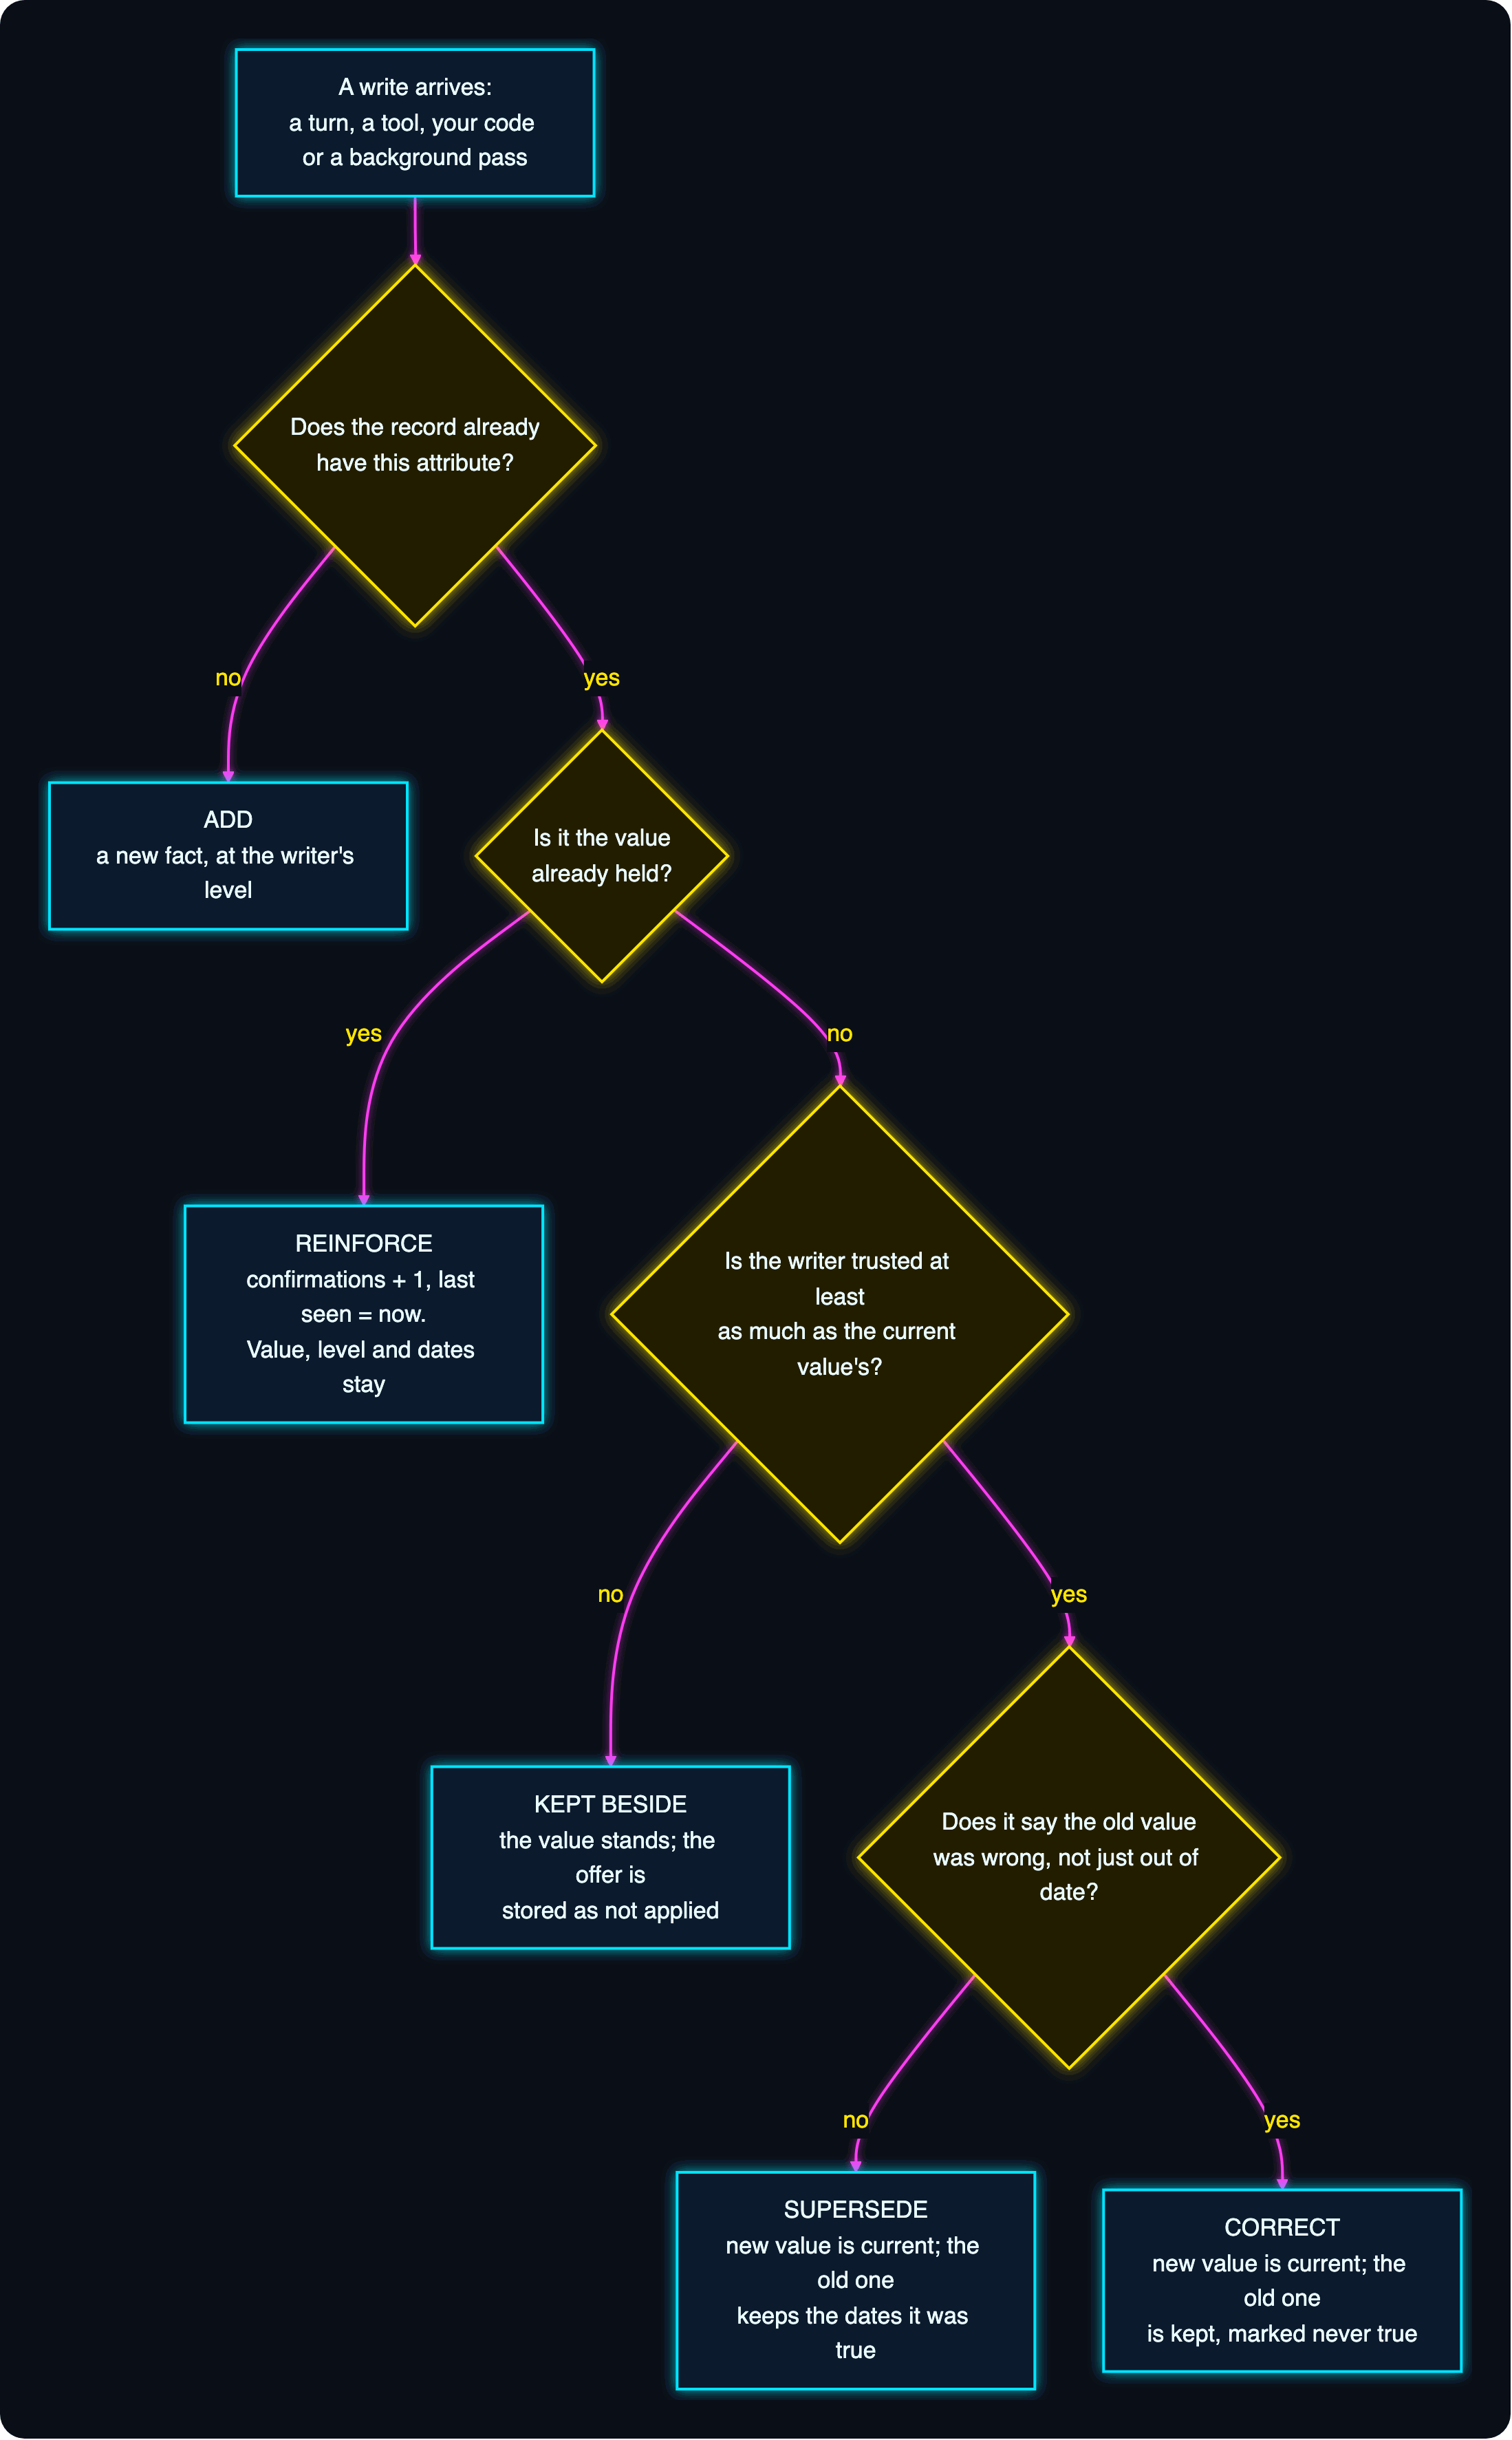

**How to read it.** Start at the top with any write — from a turn, a tool, your own
code or a background pass. Each diamond is a question the store asks; each coloured box
at the bottom is what it does.

| Outcome | When it applies | How it ends | Where you'll see it |
|---|---|---|---|
| **Add** | The record has no such attribute yet | A new fact, at the writer's level | Monday |
| **Reinforce** | The value is the one already held | `confirmations` goes up, `last_seen` moves. Value, level and dates stay | Tuesday, and again on Thursday |
| **Kept beside** | A different value, from a *weaker* source | The current value stands; the offer is stored as `applied: False` | Wednesday's rumour, Thursday's £4,000 |
| **Supersede** | A different value, from an equal or stronger source | The new value is current; the old one keeps the dates it was true | Wednesday: the office, Drop, the January limit |
| **Correct** | Equal or stronger source, and it says the old value was *wrong* (same `valid_from`, or `correction: True`) | The old value is kept, marked "never true" | Wednesday: a typo in the Senior limit |

Two more operations aren't in the picture because they aren't about one write.
**Resolve** is finding the right record in the first place ("CFU", "the fraud team" and
"Counter Fraud Unit" are one thing). **Merge** is what consolidation does when it finds
that one thing filed twice. Both are Part 5.

### The same rule, over our week

Here is the rule as it plays out for the one attribute that matters most, the Grade 1
limit. Read it top to bottom.

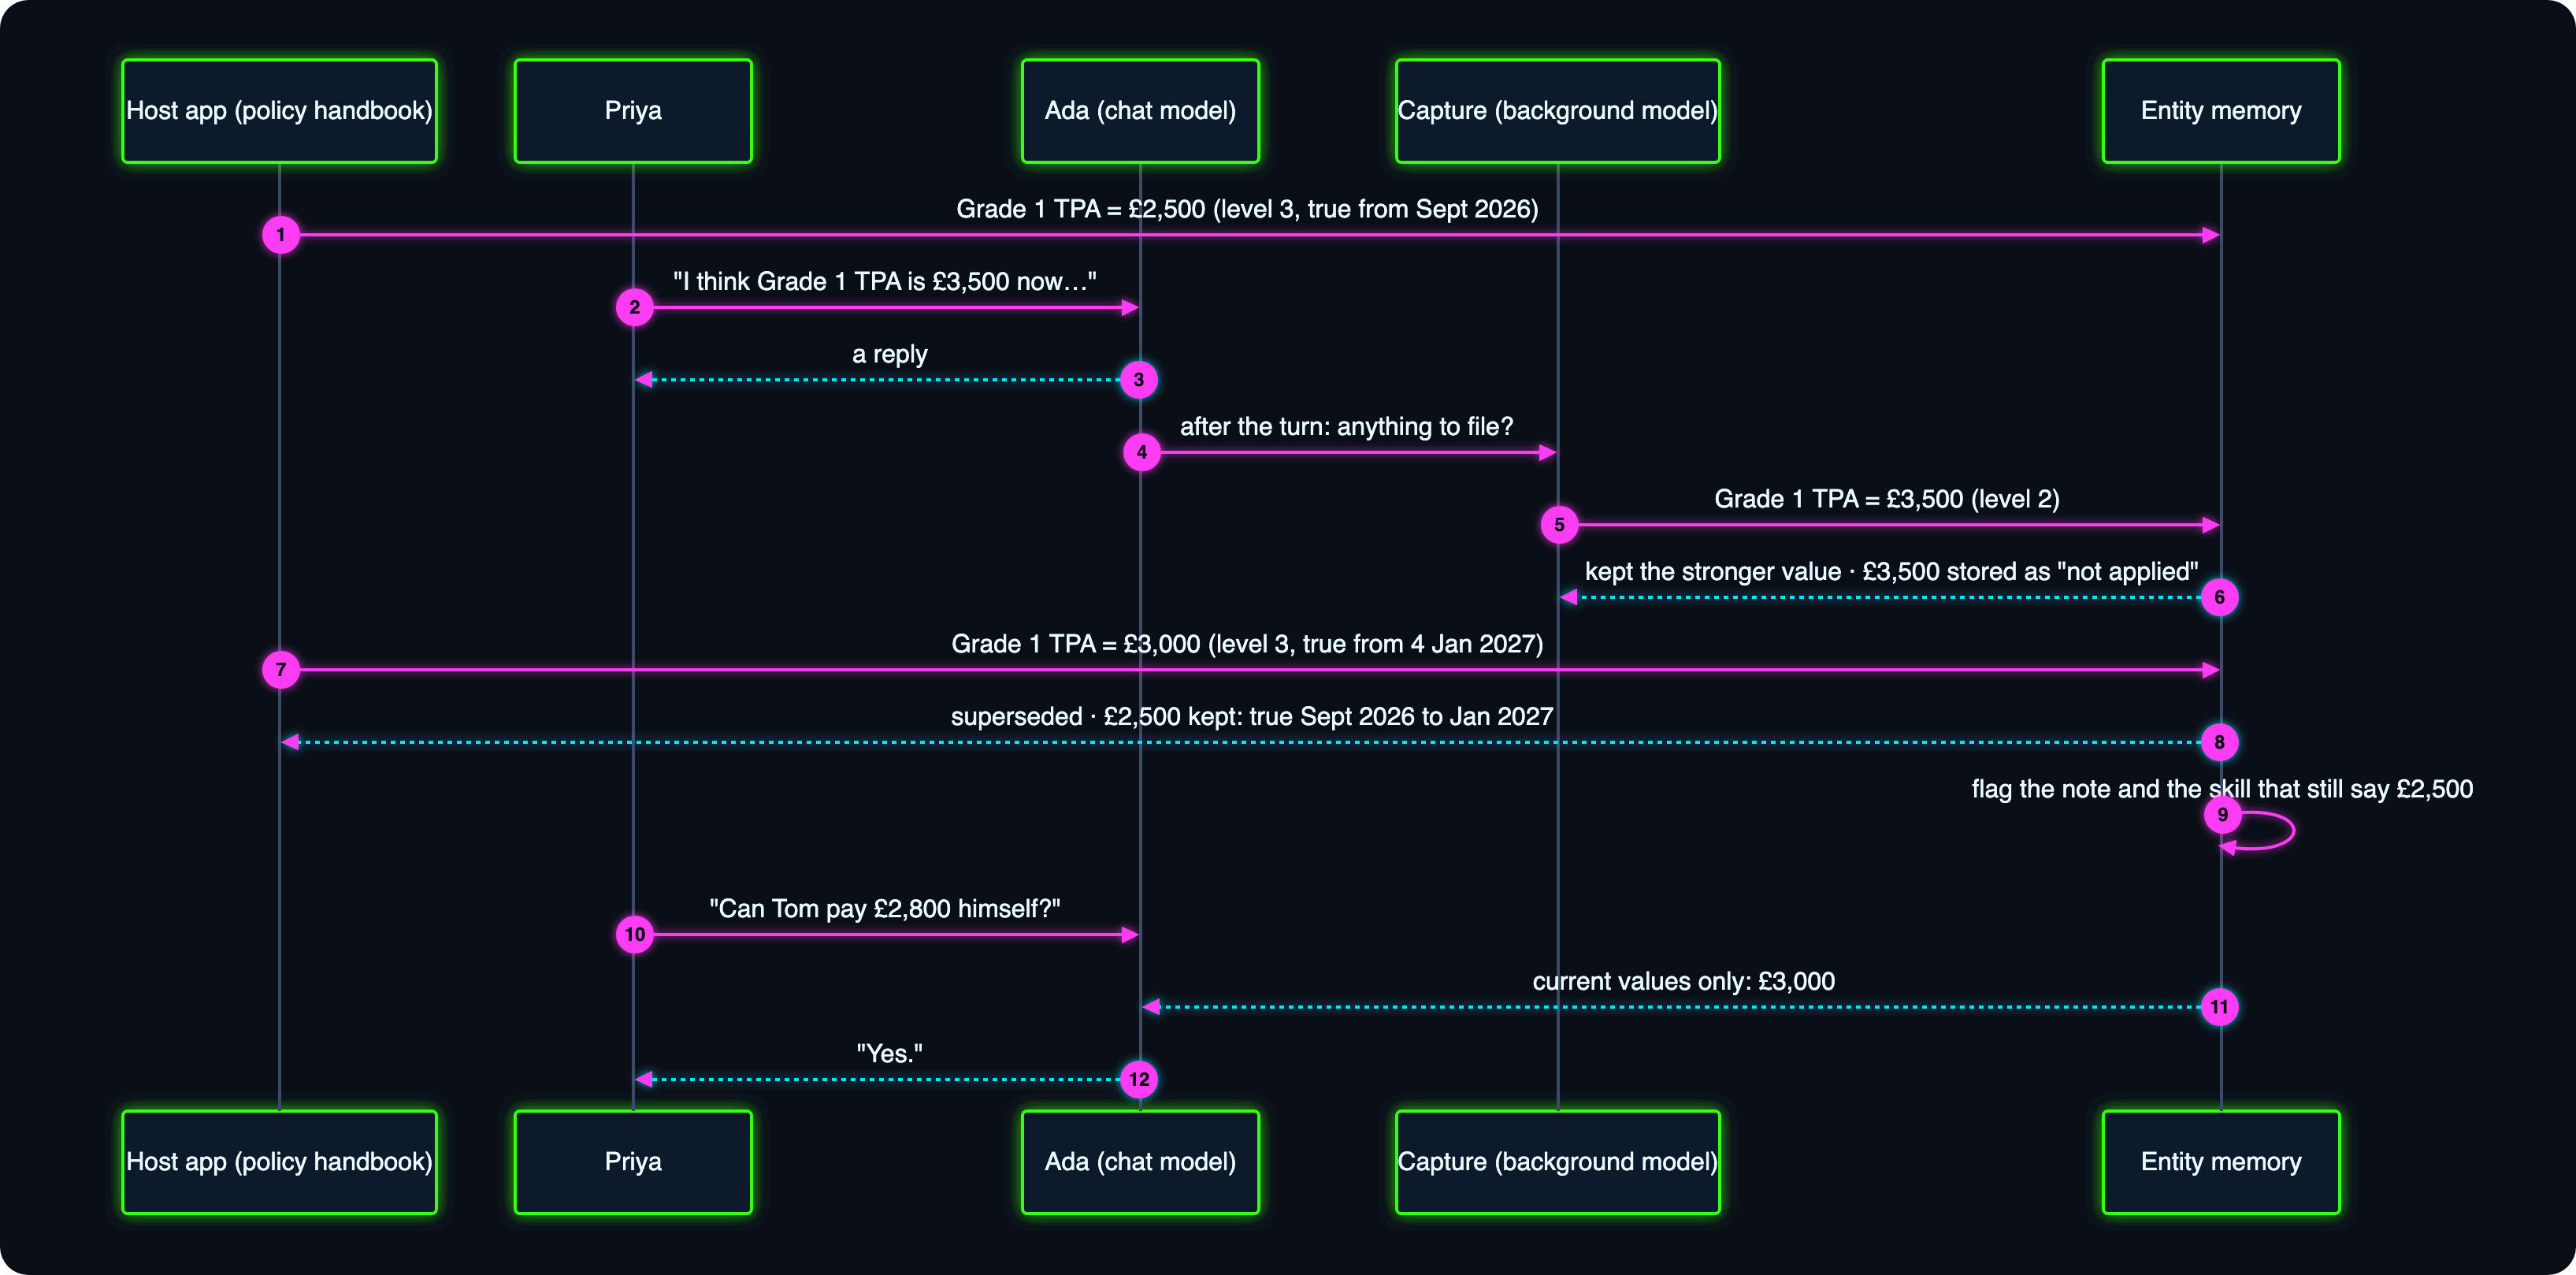

**How to read it.** Time runs downwards. An arrow into *Entity memory* is a write; the
arrow back is what the store did with it. Step 6 is the refusal (a level-2 remark
against a level-3 value), step 8 the supersession (level 3 against level 3), and step 9
is the change leaving the record: the texts that still quote £2,500 get flagged.

The store keeps everything. The prompt gets only what is current. That split is the
design.

### The week at a glance

Six days, and who did what to memory on each.

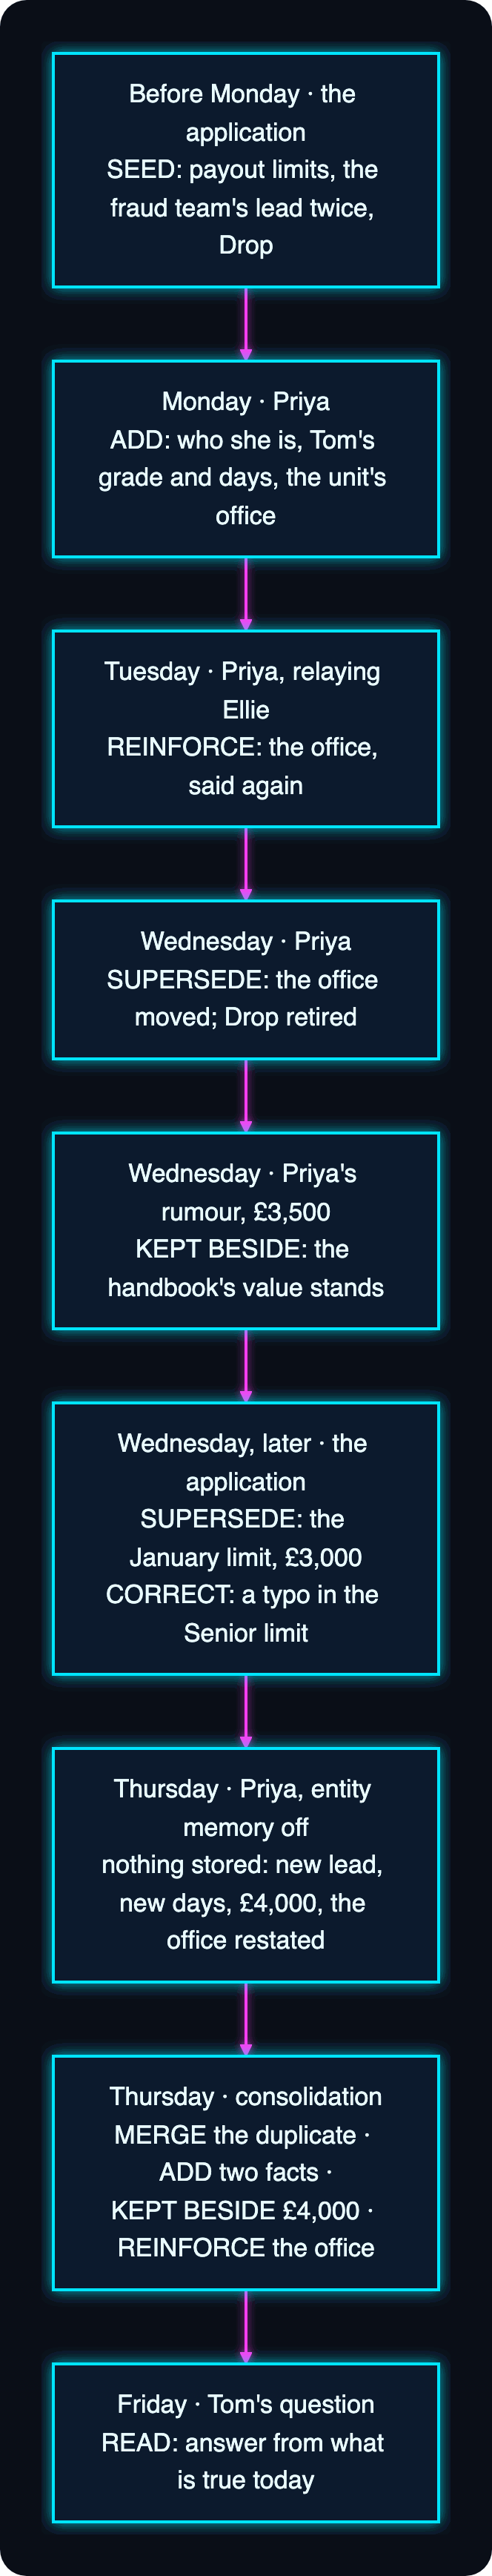

**How to read it.** One box per day, in order. The first line is who spoke or wrote,
the second is what it did to the record, in the vocabulary of the table above.

| Day | Who | What reaches memory | Operation |
|---|---|---|---|
| Before Monday | The application | Payout limits from the handbook; two leftovers from old conversations | Seed |
| Monday | Priya, in conversation | Who she is, Tom's grade and days, where the fraud team sits | Add |
| Tuesday | Priya, relaying Ellie | The fraud team's office, again | Reinforce |
| Wednesday | Priya, in conversation | The office moved; Drop is retired; a rumour about the limit | Supersede, supersede, kept beside |
| Wednesday, later | The application | The January limit; a typo fixed | Supersede (and flags), correct |
| Thursday | Priya, with entity memory off | A new lead, new days, a wrong limit, the office restated | Nothing — until consolidation: merge, add, kept beside, reinforce |
| Friday | Tom's question | Nothing is written | Read |

## The data in this notebook

Nothing here is loaded from a file. Every record, message and question is typed into a
cell, so you can see all of it — but it arrives in pieces, so here is the whole of it in
one place first.

**Words you'll need** (Calderwood is fictional, and so is its vocabulary):

| Term | What it means at Calderwood |
|---|---|
| **Claims handler** | The person who works a customer's insurance claim. Handlers have a **grade**: Grade 1 is the junior grade, then Grade 2, then Senior Handler |
| **TPA** | *Total Payout Authority*: the most a handler may pay on one claim without asking someone more senior. £2,500 for Grade 1 in the autumn |
| **Policy handbook** | Calderwood's rule book. It is where the TPA limits are set, so it is the authority on them |
| **Counter Fraud Unit (CFU)** | The team that investigates suspected fraud. People also call it "the fraud team" |
| **Amber Pack** | The bundle of papers a handler sends to the CFU when a claim looks suspicious |
| **Beacon** | The claims system. A claim reference looks like `CW-512904` |
| **Drop, Compass** | The website customers upload large files through. Drop is the old one; Compass replaces it in January 2027 |
| **Desk Lead** | A handler's manager (here: Dev) |

**The data, by group:**

| Group | How many | Used in | What it is for |
|---|---|---|---|
| **Seeded records** | 4 records holding 7 values | Part 3 | What the application already knows before anyone speaks: three payout limits (one with a typo), the fraud team's lead (filed twice, under two names), and the Drop portal |
| **Written-down texts** | 2 notes and 1 skill | Part 3, then Parts 4 and 5 | Things outside entity memory that *quote* the seed. They exist so that we can watch what happens to them when the seed changes |
| **The week's lines** | 11 sentences from Priya, over 4 days | Parts 4 and 5 | The conversation. Each line is one fact said to Ada (and, word for word, to her twin) |
| **Writes from the application** | 4 | Part 4 | One rumour written by hand to show a refusal, one confirmation, the real January limit, and the typo's correction |
| **The truth of the week** (`SUPERSEDED`) | 5 rows | Part 5 | For each fact that changed: what it must say now, and what it must no longer say. The regression test |
| **Friday's questions** (`QUESTIONS`) | 5 | Part 6 | The exam. Each carries its right answer and the stale answers it might attract |

**How to read one seeded value.** A record is a name, a type and a list of attributes;
each attribute is a small dictionary. Taking the Grade 1 limit as the example:

| Field | In the example | Meaning |
|---|---|---|
| record `name` | `"Total Payout Authority"` | Which real-world thing this is about |
| `entity_type` | `"policy"` | What kind of thing (a policy, a team, a system, a person) |
| attribute `name` | `"grade_1"` | Which fact about it |
| `value` | `"£2,500"` | The fact itself, as text |
| `source` | `"policy_handbook"` | Free-text note of where it came from |
| `valid_from` | `"2026-09-01"` | Optional: when it became true in the world. Leave it out and the store uses the moment of the write |
| level | 3 (not written; a direct SDK call is the host) | How much the write is trusted. Pass `source_level=2` to mark it as "a user said this" |

**How to read one line of the week.** A line is `say(day, text)`:

| Field | In the example | Meaning |
|---|---|---|
| `day` | `"wednesday"` | Which conversation the line belongs to. One conversation per day |
| `text` | `"Quick note: the Counter Fraud Unit moved to the Manchester office last week."` | What Priya types. Ada gets it, then her twin gets the same words |
| the right outcome | the office becomes Manchester; Leeds is kept with its dates | Not part of the call. The checks after each cell assert it |

The lines come in five kinds, and each has a different right outcome: **new** facts
(added), a **repeat** (confirmed, value unchanged), **contradictions between equals**
(the newer one wins), **claims against the handbook** (kept beside, never applied),
and Thursday's lines, which are **said while entity memory is off** (nothing stored
until consolidation reads the transcript).

`SUPERSEDED` and `QUESTIONS` are explained where they appear, in Parts 5 and 6.

# Part 2 · Setup

Plumbing, but deliberate plumbing. This part gets you a place for memory to live, the two models that will do the talking and the learning, the Calderwood world as importable data, and a journal that records every write. By the end you'll have a `provider` object — the one thing every later cell reads and writes through — and you'll know why the chat model and the background model are separate settings.

## 0 · Setup

Three things happen in the next few cells, and each one is deliberate.

1. **MemoRizz is installed from PyPI.** The first cell runs
   `pip install --upgrade "memorizz[ui,filesystem]"`: the latest release, with
   the local UI (`ui`) and the FAISS-backed file store (`filesystem`). These
   notebooks need MemoRizz 0.17.25 or later. Keep `calderwood_world.py` in the
   same folder as the notebook; it is plain data, imported from here.
2. **The store is a folder you can open.** `FileSystemProvider` is the
   zero-infrastructure backend — every memory is a JSON document on disk. All
   five notebooks write to the same folder, `calderwood_store`, next to the
   notebooks, so the whole series ends up in one place **and the MemoRizz
   local UI can connect to it** (the last section shows how). Delete the
   folder to start again. Oracle and MongoDB are a provider swap, not a
   rewrite.
3. **One small, current model.** Both the *chat model* (which answers the
   user) and the *background model* (which does the learning, off the user's
   turn) default to `gpt-6-luna`, the cheapest of OpenAI's current models.
   They are separate settings on purpose: learning is not on anyone's
   critical path, so it is the first place to spend on a stronger model if
   you want one.

You need an `OPENAI_API_KEY` in the environment (or in a `.env` file in this
folder or any folder above it). The key is read from the environment and never written
into the notebook or the store.

The first cell is plumbing, and only two names in it matter:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `%pip install --upgrade "memorizz[ui,filesystem]"` | Notebook magic | Installs the latest MemoRizz release into this notebook's kernel, with the local UI and the file store's vector index | One line, and the notebook runs anywhere. Restart the kernel if it upgrades a MemoRizz that was already imported |
| `OPENAI_API_KEY` | Environment variable | Read from the environment, or from the repository's `.env` | Every model call and every embedding in the notebook uses it; it is never printed |

In [1]:
import json
import logging
import os
import sys
import tempfile
import uuid
from pathlib import Path

# 1. MemoRizz from PyPI: the latest release, with the local UI and the file store's vector index.
%pip install --quiet --upgrade "memorizz[ui,filesystem]"

# The key comes from the environment, or from a .env file in this folder or above it.
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**Next: where memory lives, which models do the work, and the world we're in.** Everything later leans on what this cell sets.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `FileSystemProvider` | MemoRizz API | The *memory provider*: the object every agent reads and writes its memory through. This one keeps each memory as a JSON document in a folder | Zero infrastructure, and the local UI can open the same folder. Swap it for Oracle or MongoDB and nothing else in the notebook changes |
| `FileSystemConfig(root_path=..., embedding_provider=..., embedding_config=...)` | MemoRizz API | Where the folder is, and how text is turned into vectors for search | A small OpenAI embedding model at 256 dimensions: cheap, and plenty for a fixture this size |
| `MemAgent`, `MemoryType` | MemoRizz API | The agent class, and the enum of memory types | Imported now, used from Part 3 |
| `MEMORIZZ_HOME` | MemoRizz API (environment) | Where MemoRizz keeps its own settings | Pointed at a throwaway folder, so nothing here touches a MemoRizz setup you already have |
| `CHAT_MODEL`, `BACKGROUND_MODEL` | notebook helper (settings) | The model that answers the user, and the model that does the learning off the user's turn | Two jobs. They're the same model here only because it's the cheapest |
| `calderwood_world` (as `cw`) | Calderwood data | A small module beside the notebooks: Calderwood's people, teams, systems and limits. Plain data; it doesn't import MemoRizz | Every notebook reads names and figures from it, so the Grade 1 limit this notebook supersedes is the same number notebook 01 pays claims against |
| `RUN` | notebook helper | A short random suffix added to every id | The store is shared across the series; the suffix keeps this run's agents apart from yesterday's |

In [2]:
# 2. One store for the whole series, in a folder the local UI can open.
STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "calderwood_store").resolve()
os.environ["MEMORIZZ_HOME"] = tempfile.mkdtemp(prefix="memorizz-nb-home-")  # leave your own MemoRizz home alone
logging.disable(logging.WARNING)  # keep the lesson's output readable

import memorizz
from memorizz import FileSystemConfig, FileSystemProvider, MemAgent, MemoryType

import calderwood_world as cw  # Calderwood's people, teams, systems and limits

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)

# 3. The cheapest current model, for both jobs. Override either from the environment.
CHAT_MODEL = os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")
BACKGROUND_MODEL = os.getenv("MEMORIZZ_NB_BACKGROUND_MODEL", "gpt-6-luna")
RUN = uuid.uuid4().hex[:6]  # keeps ids unique if you re-run the notebook

**Last piece of setup: two helpers for finding this run in the UI.** Neither teaches anything about learning. `record_run` writes this run's agent and conversation ids to a small JSON file in the store, and `ui_command` builds the command that opens the store in the MemoRizz local UI. Both get used once, at the very end.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `record_run(notebook, **ids)` | notebook helper | Writes this run's agent, memory and conversation ids to `notebook_runs.json` in the store | So the pages for *this* run are easy to find among several |
| `ui_command()` | notebook helper | Builds the `memorizz ui` command that opens the store, with the embedding settings it needs | The UI has to embed queries the same way the notebook did |

In [3]:
def record_run(notebook, **ids):
    """Note which agents and conversations this run made, so they are easy to find in the UI."""
    path = STORE / "notebook_runs.json"
    runs = json.loads(path.read_text()) if path.exists() else {}
    runs[notebook] = {"run": RUN, **ids}
    path.write_text(json.dumps(runs, indent=2))


def ui_command():
    """The command that opens this store in the MemoRizz local UI."""
    return (
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path {STORE.name}"
    )


print("memorizz      :", getattr(memorizz, "__version__", "dev"), "(installed from PyPI)")
print("store         :", STORE.name, "(a folder beside this notebook)")
print("chat model    :", CHAT_MODEL, "| background model:", BACKGROUND_MODEL)
print("run id        :", RUN)

memorizz      : 0.17.24 (from src/)
store         : calderwood_store (a folder beside this notebook)
chat model    : gpt-6-luna | background model: gpt-6-luna
run id        : cf6f8f


One extra line for this notebook. **Memory history is a journal of every write to the
store: what changed, who wrote it and why.** The local UI switches it on for itself;
an SDK provider opts in. We turn it on here so that, at the end, the UI's *Memory
evolution* page can show this week as a timeline of changes rather than a final state.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `enable_memory_history(provider)` | MemoRizz API | Turns on the write journal for a provider: every create, update, merge and retire is recorded with its writer and reason | Without it the UI can show the final state of this week, but not how memory got there |

In [4]:
from memorizz.memory_history import enable_memory_history

enable_memory_history(provider)
print("write history: on for this provider")

write history: on for this provider


# Part 3 · The world before Monday

No model runs in this part until the very end. First you'll write what the application already knows into entity memory, the way a real deployment would; then build the handful of helpers we use to read the store; then meet the two agents. By the end you'll have four records at two trust levels, a tool that reads a fact's past, Ada and her twin differing in exactly one respect, and three pieces of text that quote the seed.

## 1 · Before Monday: what the host already knows

We start where most real deployments start: the application already knows some things,
and it writes them before any conversation happens. Three writes, in two kinds.

**The policy handbook's figures.** One entity, *Total Payout Authority*, with an
attribute per grade. The call is `EntityMemory.upsert_entity`, and a direct SDK call
is host code, so these land at **level 3** without us asking. Each value also carries
a `valid_from`: the host knows the handbook set these limits in September 2026, and
says so. (Hold on to that date; Friday has a question about September.)

There are three limits, one per grade. Look closely at the third when it prints: the
Senior limit is £50,000, and the import that loaded it **dropped a zero**. Nobody has
noticed yet. We'll need a mistake later, to show how fixing one differs from a change.

The figures themselves come from `cw.tpa(...)`, the shared Calderwood module, so
nobody types £2,500 twice.

**What earlier conversations left behind.** Two leftovers, written with
`source_level=2` because they stand for things a handler once said:

- who leads the Counter Fraud Unit — filed twice by a sloppy capture, once on the
  "Counter Fraud Unit" record and once on a record named "CFU";
- that customers upload large files through a portal called Drop.

Two records for one team. We'll leave that wrong for now — fixing it is Part 5.

A word on scope. Every read and write below carries a `memory_id` and a `user_id`.
That pair is what makes these facts *this handler's desk's* facts: Priya's. (All five
notebooks share one store folder, so the scope is also what keeps this notebook's
records apart from the others'.)

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `EntityMemory(provider)` | MemoRizz API | The entity store over a provider: create, update, look up and list entity records | Host code talks to it directly; an agent goes through the same store |
| `entities.upsert_entity(name=..., entity_type=..., attributes=[...], memory_id=..., user_id=...)` | MemoRizz API | Creates the record or updates it. With no `source_level` it is a host write: **level 3** | How the handbook's figures get in, and later how they change |
| an attribute: `{"name", "value", "source", "valid_from"}` | MemoRizz API (data shape) | One fact (the fields are laid out in *The data in this notebook*, Part 1). `valid_from` is optional and says when the value became true in the world | `valid_from` is how the host records "since September 2026" |
| `SCOPE` | notebook helper | The `memory_id` and `user_id` every call carries | Whose facts these are |
| `cw.tpa(handler)`, `cw.pounds(amount)` | Calderwood data | A handler's payout limit in a given round, and an amount formatted as £2,500 | One spelling of every figure |
| `attribute_timeline`, `entity_aliases`, `source_level` | MemoRizz API | Readers for a fact's history, a record's other names and a value's trust level | Imported here, explained where each is first used |

In [5]:
from memorizz.long_term.semantic.entity_memory.entity_memory import (
    EntityMemory,
    attribute_timeline,
    entity_aliases,
    source_level,
)

MEMORY_ID = f"calderwood03-{RUN}"
USER_ID = cw.USER_IDS["Priya Shah"]
SCOPE = {"memory_id": MEMORY_ID, "user_id": USER_ID}
entities = EntityMemory(provider)

# Host code: the policy handbook is the authority on payout limits (level 3 by default).
HANDBOOK_SINCE = "2026-09-01T00:00:00+00:00"  # when the handbook set these limits
GRADE_1 = cw.pounds(cw.tpa("Tom Okafor"))  # round 1: £2,500
GRADE_2 = cw.pounds(cw.tpa("Priya Shah"))  # £10,000
SENIOR_TYPO = "£5,000"  # should be £50,000: the import dropped a zero
entities.upsert_entity(
    name="Total Payout Authority",
    entity_type="policy",
    attributes=[
        {"name": "grade_1", "value": GRADE_1, "source": "policy_handbook", "valid_from": HANDBOOK_SINCE},
        {"name": "grade_2", "value": GRADE_2, "source": "policy_handbook", "valid_from": HANDBOOK_SINCE},
        {"name": "senior", "value": SENIOR_TYPO, "source": "policy_handbook", "valid_from": HANDBOOK_SINCE},
    ],
    **SCOPE,
)

'50d22ba2-3991-54a0-85bc-04c3a5f97e69'

**And the leftovers.** This cell adds the three remaining records: the fraud team's lead, twice, and the Drop portal. Same call, with `source_level=2`, because they stand for things a handler once said rather than things the handbook says. The fraud team's lead comes
from `cw.TEAMS`; the loop writes it under both of the team's names, which is the
duplicate.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `source_level=2` | MemoRizz API (parameter) | Marks a write as "stated by a user" rather than by the host | These facts must stay correctable by conversation; at level 3 they wouldn't be |
| `cw.TEAMS` | Calderwood data | Calderwood's teams, with their aliases and leads | Where "Nadia Hussain" comes from |

In [6]:
CFU_LEAD = cw.TEAMS["Counter Fraud Unit"]["lead"]  # Nadia Hussain
for name in ("Counter Fraud Unit", "CFU"):
    entities.upsert_entity(
        name=name,
        entity_type="team",
        attributes=[{"name": "lead", "value": CFU_LEAD, "source": "turn"}],
        source_level=2,
        **SCOPE,
    )

entities.upsert_entity(
    name="Drop",
    entity_type="system",
    attributes=[
        {"name": "purpose", "value": "customer upload portal for large files", "source": "turn"},
        {"name": "status", "value": "in use", "source": "turn"},
    ],
    source_level=2,
    **SCOPE,
)
print("seeded 4 records in memory", MEMORY_ID)

seeded 4 records in memory calderwood03-cf6f8f


Next, two small lookups we'll lean on for the rest of the notebook. A model chooses attribute names (`location` in one run, `office_location` in the next), so we find attributes by a word in the name rather than by an exact match.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entities.get_entity_by_name(name, memory_id=..., user_id=...)` | MemoRizz API | The live record with exactly this name, in this scope | The normal way to fetch a record |
| `entities.get_entity_by_alias(name, ...)` | MemoRizz API | The live record that lists this name as an alias | After a merge, "CFU" is an alias, not a record |
| `find_entity(name)` | notebook helper | Tries the name, then the alias | One call that works before and after the merge |
| `find_attribute(record, *words)` | notebook helper | The first attribute whose name contains one of the words | Survives the model's choice of attribute names |

In [7]:
def find_entity(name):
    """The live record with this name, or the one that lists it as an alias."""
    return entities.get_entity_by_name(name, **SCOPE) or entities.get_entity_by_alias(
        name, **SCOPE
    )


def find_attribute(record, *words):
    """The first attribute whose name contains one of the words."""
    for attribute in (record or {}).get("attributes") or []:
        if any(word in attribute["name"].lower() for word in words):
            return attribute
    return None

**And a printer for the whole store.** We'll call this after every day of the week, so
it's worth knowing how to read its output: one block per record, one line per
attribute, the source level on the left.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entities.list_entities(memory_id=..., user_id=...)` | MemoRizz API | Every live record in a scope. Records merged away by consolidation are not listed | "How many entities" is the first thing a merge changes |
| `entity_aliases(record)` | MemoRizz API | The other names a record answers to | Empty until Part 5's merge |
| `source_level(attribute)` | MemoRizz API | The trust level (3, 2 or 1) stored on a value | The `L3` / `L2` / `L1` column: who would be allowed to change it |
| `show_entities(label)` | notebook helper | Prints every record with its type, aliases and attributes, and how many earlier values each attribute holds | Our view of the store after each day |

In [8]:
def show_entities(label):
    records = entities.list_entities(**SCOPE)
    print(f"== {label}: {len(records)} entities ==")
    for record in records:
        aliases = entity_aliases(record)
        also = f"  (also known as: {', '.join(aliases)})" if aliases else ""
        print(f"{record['name']} [{record.get('entity_type')}]{also}")
        for attribute in record.get("attributes") or []:
            earlier = len(attribute.get("history") or [])
            note = f"  · {earlier} earlier" if earlier else ""
            print(
                f"    L{source_level(attribute)}  {attribute['name']} = "
                f"{attribute.get('value')}{note}"
            )
    return records

**Two views of the past.** Entity memory doesn't overwrite; it keeps what it knew. These helpers print that.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `attribute_timeline(attribute)` | MemoRizz API | Every value an attribute has held or been offered, current first. Each row has `value`, the valid-time dates `valid_from` and `valid_to`, the recorded-time dates `recorded_at` and `superseded_at`, `level`, `source`, `confirmations`, `last_seen`, and three flags: `current`, `applied` (false for a write that was offered and refused) and `corrected` (true for a value that was wrong rather than out of date) | The whole "supersede, don't delete" story is in these rows |
| `now()` | notebook helper | This instant as an ISO timestamp, the way the store stamps a write | We take one mid-week, to ask later what the store believed at that moment |
| `when(stamp)` | notebook helper | Shortens a timestamp to date and minute | Dates matter here: one of them is September |
| `show_timeline(record, attribute)` | notebook helper | Prints the timeline, one value per line, as *current since*, *was current from → to*, *CORRECTED* or *offered, NOT applied*, with the confirmation count when there is one | That last state matters: a claim the source rule turned down is still on the record |

In [9]:
from datetime import datetime, timezone


def now():
    """This instant, as the store stamps a write (UTC, ISO)."""
    return datetime.now(timezone.utc).isoformat()


def when(stamp):
    """2026-09-01 09:00, from an ISO timestamp."""
    stamp = str(stamp or "")
    return f"{stamp[:10]} {stamp[11:16]}" if stamp else "…"


def show_timeline(record, attribute):
    print(f"{record['name']} · {attribute['name']}")
    for row in attribute_timeline(attribute):
        if row["current"]:
            state = f"current since {when(row['valid_from'])}"
        elif row.get("corrected"):
            state = "CORRECTED: this value was never true"
        elif row["applied"]:
            state = f"was current {when(row['valid_from'])} → {when(row['valid_to'])}"
        else:
            state = f"offered {when(row.get('offered_at'))}, NOT applied"
        if row.get("confirmations"):
            state += f" · confirmed {row['confirmations']}×"
        print(f"    L{row['level']}  {str(row.get('value')):<20} {state:<52} source: {str(row.get('source'))[:28]}")

**Both clocks, side by side.** `show_timeline` prints one date range per value: when it was true. The store keeps a second range, when it *believed* the value, and from Wednesday the two stop agreeing. `show_clocks` prints them next to each other.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `show_clocks(record, attribute)` | notebook helper | One line per value that was ever applied: the dates it was true in the world (`valid_from` → `valid_to`) and the dates this store believed it (`recorded_at` → `superseded_at`). A corrected value reads *never* under "true" | The difference between a change and a correction is only visible with both columns |

**And the second shelf.** A value replaced turn by turn goes into the attribute's history,
which `show_timeline` prints. A value replaced by a *consolidation pass* is retired
instead: moved to the record's metadata, where nothing reads it but an undo. This
helper prints that shelf (it stays empty until Part 5).

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `show_retired(record)` | Notebook helper | Prints each value in the record's `metadata["retired_attributes"]`: its name, value, source level, when it was retired and by which plan | Shows that a consolidation pass retires a value rather than deleting it, so an undo has something to bring back |

In [10]:
def show_clocks(record, attribute):
    """One line per value that was ever applied, with both clocks."""
    print(f"{record['name']} · {attribute['name']}")
    print(f"    {'value':<10}{'true in the world':<28}{'believed by this store'}")
    for row in attribute_timeline(attribute):
        if not row["applied"]:
            continue
        until = when(row["valid_to"])[:10] if row["valid_to"] else "now"
        world = "never (corrected)" if row.get("corrected") else f"{when(row['valid_from'])[:10]} → {until}"
        stopped = when(row["superseded_at"]) if row["superseded_at"] else "now"
        print(f"    {str(row['value']):<10}{world:<28}{when(row['recorded_at'])} → {stopped}")


def show_retired(record):
    """Values a consolidation pass took out of use. Kept, never rendered."""
    for item in (record.get("metadata") or {}).get("retired_attributes") or []:
        print(
            f"    retired  {item['name']} = {item.get('value')}  (was L{source_level(item)}, "
            f"retired {when(item.get('retired_at'))} by {str(item.get('retired_by'))[:24]}…)"
        )

**A soft assertion, and a first look.** `check` prints a tick or a cross and carries on, because a live model is in the loop and we'd rather see a miss than hide it. Then we print the store as the host seeded it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `check(label, ok)` | notebook helper | Prints ✓ or ✗ and returns the result | Every claim this notebook makes about the store is one of these |

In [11]:
def check(label, ok):
    print(("✓ " if ok else "✗ ") + label)
    return bool(ok)


_ = show_entities("seeded by the host")

== seeded by the host: 4 entities ==
Total Payout Authority [policy]
    L3  grade_1 = £2,500
    L3  grade_2 = £10,000
    L3  senior = £5,000
Counter Fraud Unit [team]
    L2  lead = Nadia Hussain
CFU [team]
    L2  lead = Nadia Hussain
Drop [system]
    L2  purpose = customer upload portal for large files
    L2  status = in use


Read the left-hand column first. `L3` on the payout limits, `L2` on the team lead and
on Drop: the level is stored on the value itself, so the rule can be applied later
without anyone remembering who wrote what. (And there is the typo: `senior = £5,000`.
Leave it.)

### A window onto the past

One more piece before the agents. History, as we'll see, is **never** put in the
prompt — which is the point, but it does mean the model can't answer "what was the
limit in September?" from what it's shown. So we give it a way to ask.

MemoRizz has the question built in: `EntityMemory.value_as_of(attribute, date, ...)`
returns the value that was true on a date. `fact_as_of` below is a thin wrapper that
makes it a tool: it finds the record and the attribute by name, calls `value_as_of`,
and hands back plain data. Given to an agent, it turns the audit trail into something
the assistant can consult on the rare turn that needs it, at zero cost on the turns
that don't. `HISTORY_CALLS` just notes each use so we can see, later, whether Ada
reached for it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entities.value_as_of(attribute, when, entity_id=..., memory_id=..., user_id=...)` | MemoRizz API | The timeline row that was true on the date `when` (a date or a timestamp), or `None`. A value that was later *corrected* is never returned: it was never true | The point-in-time read. Part 4 adds its second argument, `known_at` |
| `fact_as_of(entity, attribute, date)` | notebook helper, given to Ada as a tool | Looks the fact up by name and returns its value on that date, with the dates it held | Lets the assistant answer "what was it in September?" without history sitting in every prompt |
| `HISTORY_CALLS` | notebook helper | A list of the `(entity, attribute, date)` the tool was asked for | So we can see whether Ada used it on Friday |

In [12]:
HISTORY_CALLS = []


def fact_as_of(entity: str, attribute: str, date: str) -> dict:
    """The value a recorded fact had on a date (YYYY-MM-DD): what was true in the world then.
    Use it for questions about what something used to be."""
    HISTORY_CALLS.append((entity, attribute, date))
    record = find_entity(entity)
    if not record:
        return {"found": False, "entities": [r["name"] for r in entities.list_entities(**SCOPE)]}
    held = find_attribute(record, attribute.lower().replace(" ", "_"))
    if not held:
        return {"found": False, "attributes": [a["name"] for a in record.get("attributes") or []]}
    day = date if len(date) > 7 else f"{date}-15"  # "2026-09" means some time that month
    row = entities.value_as_of(held["name"], day, entity_id=record["entity_id"], **SCOPE)
    if not row:
        return {"found": False, "note": f"nothing on record for {date}"}
    return {
        "found": True,
        "entity": record["name"],
        "attribute": held["name"],
        "on": date,
        "value": row["value"],
        "true_from": str(row.get("valid_from") or "")[:10],
        "true_until": str(row.get("valid_to") or "")[:10] or "still current",
    }

**Try it by hand, on the seed.** One value so far, true since September — the
`valid_from` the host supplied. (We clear the call log afterwards; that call was ours,
not Ada's.)

In [13]:
print(json.dumps(fact_as_of("Total Payout Authority", "grade_1", "2026-09-30"), indent=2, ensure_ascii=False))
HISTORY_CALLS.clear()

{
  "found": true,
  "entity": "Total Payout Authority",
  "attribute": "grade_1",
  "on": "2026-09-30",
  "value": "£2,500",
  "true_from": "2026-09-01",
  "true_until": "still current"
}


### Two agents, one difference

Now the agents. **Ada** is Calderwood's claims support assistant with entity memory
switched on. Because she has a background model, MemoRizz also turns on **entity
capture: after each turn, the background model reads the user's message and files any
entity facts it states.** The chat model can write entities too, through a tool, but
capture means the record doesn't depend on the chat model remembering to.

Her instruction starts from `cw.HOUSE_INSTRUCTION` (who she is, and that amounts are
in pounds) and adds one distinction that matters for this notebook: what handlers tell
her about people, teams and systems is the latest word — but **payout limits belong to
the policy handbook**, and a figure quoted in conversation doesn't change them.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `MemAgent(...)` | MemoRizz API | An agent: a model plus the memory around it | |
| `llm_config` / `background_llm_config` | MemoRizz API (parameters) | The chat model, and the background model | Giving an agent a background model is what turns entity capture on |
| `instruction` | MemoRizz API (parameter) | The agent's standing instruction | Starts from `cw.HOUSE_INSTRUCTION`, shared by the whole series |
| `tools=[fact_as_of]` | MemoRizz API (parameter) | Plain Python functions the model may call; the docstring is the description | Ada's window onto history |
| `memory_provider`, `memory_ids` | MemoRizz API (parameters) | Where memory lives, and which memory this agent uses | Ties Ada to the records we just seeded |
| `agent_id`, `name`, `streaming=False` | MemoRizz API (parameters) | Identity, the label the UI shows, and replies returned whole | |
| `ada.with_entity_memory(True)` | MemoRizz API | Switches entity memory on: relevant records are rendered into each prompt, capture files facts after each turn, and the model gets tools to look up and write entities | The one difference between Ada and her twin |
| `ada.save()` | MemoRizz API | Stores the agent so the UI (and a later session) can load it | |

In [14]:
INSTRUCTION = (
    cw.HOUSE_INSTRUCTION
    + " Handlers tell you things about people, teams and systems as they work: take those as "
    "the latest word. Payout limits are different: they are set by the policy handbook, and a "
    "figure a handler quotes does not change them. Answer in three lines or fewer."
)

ada = MemAgent(
    llm_config={"provider": "openai", "model": CHAT_MODEL},
    background_llm_config={"provider": "openai", "model": BACKGROUND_MODEL},
    instruction=INSTRUCTION + " To see what a recorded fact was on an earlier date, call fact_as_of.",
    tools=[fact_as_of],
    memory_provider=provider,
    memory_ids=[MEMORY_ID],
    agent_id=f"ada-entities-{RUN}",
    name=f"Ada · entity memory, nb 03 ({RUN})",
    streaming=False,
)
ada.with_entity_memory(True)
ada.save()

**The control.** Same model, same instruction, and `with_entity_memory(False)`. She
will sit through every conversation Ada does, in a memory of her own, and she keeps
those conversations (MemoRizz stores them for every agent). What she doesn't have is
an entity store — so no `fact_as_of` either; there is nothing for it to read.

To keep the comparison fair, everything the host knew before Monday is given to her
the way most teams do it first: *pasted into the instruction.* She starts with the
same facts. She just can't update them.

That's the honest baseline. Not a strawman with amnesia — an assistant with a system
prompt and a chat history, which is what most assistants are.

Nothing new in the call itself: the same `MemAgent` arguments as Ada's (see the table above), minus the background model and the tool, with the day-one facts appended to `instruction` and `with_entity_memory(False)`.

In [15]:
# The control: no entity memory. What the host knows is frozen into her instruction.
TWIN_MEMORY_ID = f"calderwood03-twin-{RUN}"
twin = MemAgent(
    llm_config={"provider": "openai", "model": CHAT_MODEL},
    instruction=INSTRUCTION
    + " From the policy handbook when you were set up (September 2026): Total Payout Authority "
    f"(TPA) is {GRADE_1} for a Grade 1 handler and {GRADE_2} for a Grade 2 handler. Also on file "
    f"then: the Counter Fraud Unit (CFU) is led by {CFU_LEAD}, and customers upload large files "
    "through the Drop portal.",
    memory_provider=provider,
    memory_ids=[TWIN_MEMORY_ID],
    agent_id=f"ada-twin-{RUN}",
    name=f"Ada's twin · no entity memory, nb 03 ({RUN})",
    streaming=False,
)
twin.with_entity_memory(False)
twin.save()

**One function to talk to both.** `say` sends the same words to each assistant and prints Ada's side.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.run(text, thread_id=..., memory_id=..., user_id=...)` | MemoRizz API | One turn. `thread_id` is the conversation (one per day here), `memory_id` whose memory it is, `user_id` who is speaking | The same three ids scope everything the turn reads and writes |
| `ada.wait_for_memory_upkeep(timeout=90)` | MemoRizz API | Blocks until the background work from the last turn has finished | Capture runs *after* the reply. Without the wait, the next cell would read the store before the fact landed |
| `agent._turn_capture_mode()` | MemoRizz API (internal) | What an agent will capture from each turn | Prints `entities` for Ada and nothing for the twin: the difference, confirmed |
| `say(day, text)` | notebook helper | One line from Priya to both agents, in that day's conversation | The whole week is a sequence of these |
| `THREADS` | notebook helper | The conversation ids so far | Thursday's consolidation needs to be told which conversations to read |

In [16]:
THREADS = []


def say(day, text):
    """One user turn to Ada (printed) and the same words to the twin (not printed)."""
    thread_id = f"{day}-{RUN}"
    if thread_id not in THREADS:
        THREADS.append(thread_id)
    reply = ada.run(text, thread_id=thread_id, **SCOPE)
    ada.wait_for_memory_upkeep(timeout=90)  # let the background capture finish
    twin.run(text, thread_id=thread_id, memory_id=TWIN_MEMORY_ID, user_id=USER_ID)
    print(f"Priya: {text}\nAda:   {str(reply).strip()}\n")
    return str(reply)


print("Ada's turn capture mode :", ada._turn_capture_mode())
print("the twin's turn capture :", twin._turn_capture_mode(), "(no entity memory, nothing to capture into)")

Ada's turn capture mode : entities
the twin's turn capture : None (no entity memory, nothing to capture into)


### What else has been written down

Entity memory is not the only place a fact lives. People copy facts into notes.
Procedures quote limits. And a record that changes says nothing, by itself, to the text
that copied it.

So before the week starts we plant three pieces of text that quote the seed. They are
the *written-down texts* from the data table in Part 1, and they sit quietly until Part
4, when the facts underneath them move.

| Text | What it says | Which seeded fact it quotes | What should happen to it later |
|---|---|---|---|
| **A desk note** | Amber Packs go to the Counter Fraud Unit "in the Leeds office"; the lead is Nadia Hussain | The fraud team's office (once Priya states it on Monday) and its lead | It goes stale twice. Someone should fix it |
| **An audit note** | "September 2026: the Grade 1 TPA was £2,500 when claim CW-431255 was referred" | The Grade 1 limit | Nothing. It is a dated record of the past and is *right* to keep saying £2,500 |
| **A skill, in shadow** | A draft procedure whose step 2 reads "a Grade 1 handler's Total Payout Authority is £2,500" | The Grade 1 limit | It hard-codes a number that is about to change. Someone should decide what to do with it |

(A **skill** is a written procedure an agent can be handed, the subject of notebook 01.
*Shadow* means it is stored but not yet shown to the model, waiting for a person to
activate it. A **note** here is a knowledge-base entry: free text in the agent's
memory.)

First the two notes.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `KnowledgeBase(provider)` | MemoRizz API | The store for free-text notes and documents | Where "things someone wrote down" live |
| `notes.ingest_knowledge(text, namespace=..., chunking_strategy="none", user_id=..., metadata={...})` | MemoRizz API | Stores text as a knowledge-base entry; `"none"` keeps each note as one record. `metadata` carries the agent and the memory it belongs to | One note, one record, in Priya's memory |
| `note_row(start)` | notebook helper | The stored note that begins with these words | We'll read the notes back later to prove nobody rewrote them, and to edit one |

In [17]:
from memorizz.long_term.semantic.knowledge_base import KnowledgeBase

DESK_NOTE = (
    "Fraud referrals: an Amber Pack goes to the Counter Fraud Unit, who sit in the Leeds office. "
    f"The unit's lead is {CFU_LEAD}."
)
AUDIT_NOTE = (
    f"Audit note, September 2026: the Grade 1 TPA was {GRADE_1} when claim CW-431255 was "
    "referred to a senior handler."
)
notes = KnowledgeBase(provider)
for text in (DESK_NOTE, AUDIT_NOTE):
    notes.ingest_knowledge(
        text, namespace="desk-notes", chunking_strategy="none", user_id=USER_ID,
        metadata={"agent_id": ada.agent_id, "memory_id": MEMORY_ID},
    )


def note_row(start):
    """The stored note that begins with these words."""
    return next(
        row for row in provider.list_all(MemoryType.KNOWLEDGE_BASE)
        if row.get("memory_id") == MEMORY_ID and str(row.get("content") or "").startswith(start)
    )


print("notes in this memory:", [note_row(start)["content"][:34] + "…" for start in ("Fraud referrals", "Audit note")])

notes in this memory: ['Fraud referrals: an Amber Pack goe…', 'Audit note, September 2026: the Gr…']


**Then the skill.** A two-step draft that somebody distilled in the autumn and nobody
has activated. The second step is the problem: it writes the limit into the procedure.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Skill(name=..., description=..., content=..., preconditions=..., tools_used=..., queries=..., status=...)` | MemoRizz API | One skill record. `content` is the procedure's text | The text that quotes £2,500 |
| `SkillStatus.SHADOW` | MemoRizz API | Stored, not shown to the model | It can't affect an answer in this notebook. It can still be wrong |
| `Skillbox(memory_provider=..., agent_id=...)` | MemoRizz API | The store for an agent's skills | |
| `skills.add_skill(skill)` | MemoRizz API | Stores the skill for that agent | |

Only Ada gets these texts. Her twin has no entity memory, so nothing of hers can be
superseded and nothing could ever be flagged: there would be nothing to show.

In [18]:
from memorizz.long_term.procedural.skillbox.skill import Skill, SkillStatus
from memorizz.long_term.procedural.skillbox.skillbox import Skillbox

skills = Skillbox(memory_provider=provider, agent_id=ada.agent_id)
skills.add_skill(
    Skill(
        name="Check a payment against TPA",
        description="Use when a handler asks whether they can make a payment themselves.",
        preconditions=["The handler names a claim and an amount."],
        content=(
            "# Check a payment against TPA\n1. Look up the claim in Beacon.\n"
            f"2. A Grade 1 handler's Total Payout Authority is {GRADE_1}: refer anything above it "
            "to a senior handler."
        ),
        tools_used=["beacon_lookup_claim"],
        queries=["Can Tom pay this himself?"],
        agent_id=ada.agent_id,
        user_id=USER_ID,
        status=SkillStatus.SHADOW,
    )
)
print("skills for Ada:", [(skill.name, skill.status.value) for skill in skills.list_skills()])

skills for Ada: [('Check a payment against TPA', 'shadow')]


# Part 4 · The week: add, reinforce, supersede, refuse, correct

This is where memory starts to move. Over three days Priya tells Ada things the host
never knew, says one of them twice, contradicts two of them, and passes on a rumour
about a figure she has no authority over. Then the application changes one figure and fixes another. You'll see all five ways a
write can land (the diagram in Part 1) — added, reinforced, superseding an equal,
refused by a stronger source, corrected — and by the end of the part you'll have one
attribute with three values on file and exactly one of them in the prompt, two clocks
you can ask questions of, and three flags on texts that still quote the old world.

## 2 · Monday — add: conversation extends what the host never knew

Priya introduces herself, tells Ada what grade Tom is and when he works, and says
where the Counter Fraud Unit sits. None of this was in the seed. All of it is the kind
of thing an assistant should simply *know* by Tuesday — and one of those facts (Tom is
Grade 1) is half of Friday's answer.

**The data:** three lines, all of the *new fact* kind (see the table of line kinds in
Part 1). The right outcome for each is a new value at level 2, and no change to
anything the handbook wrote.

Nothing new to learn in the code: `say`, `show_entities` and `check` are the helpers
from Part 3. Watch the levels in the output.

(From here on, every line Priya says goes to both agents. We print Ada's replies; the
twin hears the same words and we'll come back to her on Friday.)

In [19]:
say("monday", "I'm Priya Shah, a Grade 2 handler on the home claims desk.")
say("monday", "My colleague Tom Okafor is a Grade 1 handler. He works Tuesdays to Fridays.")
say("monday", "The Counter Fraud Unit sits in the Leeds office.")

after_monday = show_entities("after Monday")
tom = find_entity("Tom Okafor")
check("a record for Tom Okafor now exists", bool(tom))
check("it says he is Grade 1", "grade 1" in json.dumps(tom or {}).lower())
check(
    "the Counter Fraud Unit gained a fact it was not seeded with",
    len(find_entity("Counter Fraud Unit")["attributes"]) > 1,
)
_ = check(
    "the handbook's Grade 1 limit is untouched",
    find_attribute(find_entity("Total Payout Authority"), "grade_1")["value"] == GRADE_1,
)

Priya: I'm Priya Shah, a Grade 2 handler on the home claims desk.
Ada:   Got it, Priya — you’re a Grade 2 handler on the home claims desk.



Priya: My colleague Tom Okafor is a Grade 1 handler. He works Tuesdays to Fridays.
Ada:   Thanks — Tom Okafor is a Grade 1 handler and works Tuesdays to Fridays.



Priya: The Counter Fraud Unit sits in the Leeds office.
Ada:   Noted — the Counter Fraud Unit is based in the Leeds office.

== after Monday: 6 entities ==
Total Payout Authority [policy]
    L3  grade_1 = £2,500
    L3  grade_2 = £10,000
    L3  senior = £5,000
Counter Fraud Unit [team]
    L2  lead = Nadia Hussain
    L2  office_location = Leeds office
CFU [team]
    L2  lead = Nadia Hussain
Drop [system]
    L2  purpose = customer upload portal for large files
    L2  status = in use
user [person]
    L2  name = Priya Shah
    L2  grade = Grade 2
    L2  role = handler
    L2  desk = home claims desk
Tom Okafor [person]
    L2  role = Grade 1 handler
    L2  work_schedule = Tuesdays to Fridays
    L2  relationship_to_user = colleague
✓ a record for Tom Okafor now exists
✓ it says he is Grade 1
✓ the Counter Fraud Unit gained a fact it was not seeded with
✓ the handbook's Grade 1 limit is untouched


**How to read that.** Three turns, and the store went from four records to a small
picture of the desk. Everything new is `L2` — stated by a user — and it sits in the
same store as the `L3` limits. Levels are per value, not per entity. One record can
hold facts from the policy handbook, from a handler and from a tool, each as
replaceable as its source deserves.

Two things you may notice, both honest properties of a model in the loop:

- **Attribute names are chosen by the model**, so yours may read `location` where
  another run reads `office_location`. The helpers match on a word, not an exact
  name, for that reason.
- **Priya's own facts are filed under `user`.** Capture files what the speaker says
  about herself under `user`, and what is said about a named person under the name.

## 3 · Tuesday — reinforce: the same thing, said twice

Ellie Burns, another handler, confirms where the unit sits, and Priya passes it on.
A colleague would do something with that: *two people have told me now; I'm surer.*
That is **reinforce** — same value, one more confirmation, a fresher "last seen" date.

**The data:** one line, of the *repeat* kind. The right outcome is that **nothing about
the value moves** — not the value, not its level, not the date it became current — and
the record gains a count.

First we just say it, and look.

In [20]:
say("tuesday", "Ellie Burns has just confirmed it: the Counter Fraud Unit is in the Leeds office.")

unit = find_entity("Counter Fraud Unit")
office = find_attribute(unit, "location", "office", "site", "based")
before = dict(office)  # the fact as it stands, to compare against in a moment
show_timeline(unit, office)
print("confirmations so far:", office.get("confirmations", 0), "| last seen:", when(office.get("last_seen")))
_ = check("the office is still Leeds", "leeds" in str(office["value"]).lower())

Priya: Ellie Burns has just confirmed it: the Counter Fraud Unit is in the Leeds office.
Ada:   Thanks, Ellie’s confirmation matches the recorded detail: the Counter Fraud Unit is in the Leeds office.

Counter Fraud Unit · office_location
    L2  Leeds office         current since 2026-11-12 15:36                       source: User stated that the Counter
confirmations so far: 0 | last seen: …
✓ the office is still Leeds


**Whether that line counted depends on the run.** Capture is a model reading a message,
and when the message says something memory already holds, a sensible model often
writes nothing at all. If the count above is 0, that is what happened. (When capture
*does* write the same value from a new conversation, MemoRizz counts it as a
confirmation by itself.)

A confirmation shouldn't hang on a model's mood, and there is a second reason to do
this one by hand. **Ellie's word only reached this memory because Priya repeated it.**
Entity memory is scoped to a `memory_id` and a `user_id`; had Ellie told Ada herself,
the fact would have landed in *Ellie's* scope. So the application carries it across:
it knows Ellie confirmed the office, and says so.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entities.reinforce_attribute(attribute, name=..., value=..., source=..., source_level=..., memory_id=..., user_id=...)` | MemoRizz API | Records that the current value was stated again: adds one to `confirmations`, sets `last_seen`, and notes who said it in `confirmed_by`. With `value`, it only counts if that is still the current value. Returns whether it counted | The reinforce operation, as one call |
| `source="ellie.burns"` | MemoRizz API (parameter) | Who confirmed. The same source is never counted twice for the same value | Five confirmations should mean five sources, not one person five times |
| `attribute["confirmations"]`, `["last_seen"]`, `["confirmed_by"]` | MemoRizz API (data shape) | The count, the date of the latest one, and the newest five confirmers | What "said twice" looks like on the record |

Then four checks, and the last three are the definition of reinforce: the value, its
source level and the date it became current are exactly what they were.

In [21]:
counted = entities.reinforce_attribute(
    office["name"], name="Counter Fraud Unit", value=office["value"],
    source="ellie.burns", source_level=2, **SCOPE,
)
unit = find_entity("Counter Fraud Unit")
office = find_attribute(unit, "location", "office", "site", "based")
print("counted:", counted)
print("confirmations:", office["confirmations"], "| last seen:", when(office["last_seen"]))
print("confirmed by :", [(item.get("source"), f"L{item.get('level')}") for item in office["confirmed_by"]])
show_timeline(unit, office)

check("the fact has at least one confirmation", office["confirmations"] >= 1)
check("the value did not move", office["value"] == before["value"])
check("nor its source level", source_level(office) == source_level(before))
_ = check(
    "nor the date it became current",
    attribute_timeline(office)[0]["valid_from"] == attribute_timeline(before)[0]["valid_from"],
)

counted: True
confirmations: 1 | last seen: 2026-11-12 15:37
confirmed by : [('ellie.burns', 'L2')]
Counter Fraud Unit · office_location
    L2  Leeds office         current since 2026-11-12 15:36 · confirmed 1×        source: User stated that the Counter
✓ the fact has at least one confirmation
✓ the value did not move
✓ nor its source level
✓ nor the date it became current


**How to read that.** Same value, same `L2`, same *current since*. What changed is the
tail of the line — *confirmed 1×* (or 2×, if capture counted Priya's relay as well) —
and the `confirmed_by` list, which says the confirmation came from Ellie at level 2.

A confirmation is deliberately weak. It **doesn't raise the level**: five handlers
agreeing do not turn a level-2 fact into a handbook entry, and the source rule never
looks at the count. What it buys is evidence. A reviewer deciding whether to trust
"the unit sits in Leeds" can now see that two people said so, and when the last one
did. And a fact nobody has confirmed in a year reads differently from one confirmed
last week.

One limit before we move on:

- **Ellie is "a user".** Level 2, same as Priya. A Desk Lead would be too. Which brings
  us to Wednesday.

## 4 · Wednesday — supersede between equals: the newer statement wins, the older one is dated

The unit has moved. That contradicts what a user said on Monday (and again on
Tuesday) — level 2 against level 2. Between equals, the newer write wins.

**The data:** one line, of the *contradiction between equals* kind. The right outcome
is Manchester as the current value **and** Leeds still on file with the dates it held.

The interesting part isn't that the value changes. It's what happens to the old one.

In [22]:
say("wednesday", "Quick note: the Counter Fraud Unit moved to the Manchester office last week.")

unit = find_entity("Counter Fraud Unit")
office = find_attribute(unit, "location", "office", "site", "based")
show_timeline(unit, office)
rows = attribute_timeline(office)
check("the current office is Manchester", "manchester" in str(rows[0]["value"]).lower())
_ = check(
    "Leeds is still on record, with the dates it was current",
    any("leeds" in str(row.get("value")).lower() and row["valid_to"] for row in rows[1:]),
)

Priya: Quick note: the Counter Fraud Unit moved to the Manchester office last week.
Ada:   Noted — the Counter Fraud Unit moved to the Manchester office last week.

Counter Fraud Unit · office_location
    L2  Manchester office    current since 2026-11-12 15:37                       source: entity_capture
    L2  Leeds office         was current 2026-11-12 15:36 → 2026-11-12 15:37 · confirmed 1× source: User stated that the Counter
✓ the current office is Manchester
✓ Leeds is still on record, with the dates it was current


**How to read that.** Each line of a timeline is one value the attribute has held:
its source level, the value, and either *current since*, or *was current from → to*.

This is the "without forgetting what it knew" in the title, made literal. Leeds didn't
vanish, and it kept its confirmations: the count belongs to the value, so the old
value takes its count into history and Manchester starts again at none. It moved to the attribute's **history** with a `valid_from` and a `valid_to`,
so the record can answer two different questions: *where is the unit?* (Manchester)
and *where was it when that November referral went out?* (Leeds). A store that
overwrites can only answer the first.

And look at what Ada *said*. "Noted", or words to that effect — and this time the
store agrees with her, because capture filed the move after the turn. An assistant
that says "I'll keep using Leeds" while its own memory says Manchester is worse than
either answer alone. That's why her instruction tells her to take what handlers say
about teams and systems as the latest word: it's what her memory is about to do
anyway.

History is kept per attribute, 20 values deep by default
(`EntityPolicy(attribute_history_limit=...)` changes that). And it costs nothing at
inference time, because history is never rendered into the prompt. We'll prove that
in a moment.

One honest gap: Priya said the unit moved *last week*. The record says Manchester has
been current since the minute she said it. Capture doesn't turn "last week" into a
`valid_from`; for a conversational write, both clocks start when the store hears about
it. Only a host write can say when something really became true — which is the next
section but one.

### A system retires

Same rule, different kind of thing. **Drop**, the customer upload portal, has been
switched off; customers use **Compass** now. This is one of Calderwood's real January
changes, and it matters to anyone who has ever told a customer where to send a video.

**The data:** one more line of the *contradiction between equals* kind. Right outcome:
Drop's status is no longer "in use", and "in use" is kept with its dates.

In [23]:
say("wednesday", "And Drop's gone. It has been retired: customers upload through Compass now.")

drop = find_entity("Drop")
status = find_attribute(drop, "status")
show_timeline(drop, status)
check("Drop is no longer 'in use'", str(status["value"]).strip().lower() != "in use")
check(
    "'in use' is still on record, with the dates it held",
    any(str(row.get("value")).lower() == "in use" and row["valid_to"] for row in attribute_timeline(status)),
)
_ = check("Compass is somewhere in memory now", "compass" in json.dumps(entities.list_entities(**SCOPE)).lower())

Priya: And Drop's gone. It has been retired: customers upload through Compass now.
Ada:   Noted — Drop is retired, and customers now upload through Compass. I’ve updated the records.

Drop · status
    L2  retired              current since 2026-11-12 15:37                       source: User update
    L2  in use               was current 2026-11-12 15:36 → 2026-11-12 15:37      source: turn
✓ Drop is no longer 'in use'
✓ 'in use' is still on record, with the dates it held
✓ Compass is somewhere in memory now


The status flipped, and the old one is dated. You'll likely see more than that: a
`replacement` attribute on Drop, perhaps a brand-new *Compass* record. One sentence
from Priya, several writes — capture files every entity fact a message states, and
"customers upload through Compass now" states something about two systems.

## 5 · Wednesday, later — a weaker source: the remark is kept beside, the value stands

Now the case that overwriting stores get wrong. Priya passes on a rumour about the
Grade 1 limit — a value in this memory that came from the policy handbook.

**The data:** one line of the *claim against the handbook* kind. The right outcome is
that the Grade 1 limit does not move, whatever Ada replies.

First we simply say it to Ada and see what she does with it.

In [24]:
say("wednesday", "I think the Grade 1 TPA is £3,500 now, though I've not seen it written down.")

tpa = find_entity("Total Payout Authority")
limit = find_attribute(tpa, "grade_1")
show_timeline(tpa, limit)
check(f"the handbook's {GRADE_1} is still the current value", limit["value"] == GRADE_1)
offered_by_turn = any(not row["applied"] for row in attribute_timeline(limit))
print("the conversation path offered the remark to the store:", offered_by_turn)

Priya: I think the Grade 1 TPA is £3,500 now, though I've not seen it written down.
Ada:   The recorded Grade 1 TPA is £2,500. Since payout limits are set by the policy handbook, I can’t change it based on an unverified figure.

Total Payout Authority · grade_1
    L3  £2,500               current since 2026-09-01 00:00                       source: policy_handbook
✓ the handbook's £2,500 is still the current value
the conversation path offered the remark to the store: False


The value held. Whether the remark was *offered* to the store depends on the run: the
model can see the stored figure and Priya's own hedge, and it often declines to write
a rumour at all (a perfectly sensible instinct). So the last line may say `False`.

That's fine for Ada, but it doesn't show you the rule. So let's make the write
ourselves — the same level-2 write the conversation path makes when it does act — and
read the report MemoRizz hands back.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entities.upsert_entity_with_report(...)` | MemoRizz API | `upsert_entity`, but returns a report of what the write did instead of just the id | We want to see the refusal, not infer it |
| `source_level=2` | MemoRizz API (parameter) | Marks the write as "stated by a user" | Without it, an SDK call counts as the host (level 3) and would win |
| `report["kept_stronger"]` | MemoRizz API (result) | Names of attributes this write could **not** replace, because the current value came from a stronger source | The source rule, reported back in one list |

In [25]:
report = entities.upsert_entity_with_report(
    name="Total Payout Authority",
    entity_type="policy",
    attributes=[{"name": "grade_1", "value": "£3,500", "source": "conversation"}],
    source_level=2,  # stated by a user
    **SCOPE,
)
print("kept_stronger:", report["kept_stronger"])

tpa = find_entity("Total Payout Authority")
limit = find_attribute(tpa, "grade_1")
show_timeline(tpa, limit)
check("the write was refused for this attribute", "grade_1" in report["kept_stronger"])
check(f"{GRADE_1} is still current", limit["value"] == GRADE_1)
_ = check(
    "£3,500 is on record as offered, not applied",
    any(row.get("value") == "£3,500" and not row["applied"] for row in attribute_timeline(limit)),
)
BEFORE_HANDBOOK_SYNC = now()  # a moment to come back to: what did the store believe just now?

kept_stronger: ['grade_1']
Total Payout Authority · grade_1
    L3  £2,500               current since 2026-09-01 00:00                       source: policy_handbook
    L2  £3,500               offered 2026-11-12 15:37, NOT applied                source: conversation
✓ the write was refused for this attribute
✓ £2,500 is still current
✓ £3,500 is on record as offered, not applied


`kept_stronger` names the attribute the write could not move. The £3,500 is in the
history, flagged as never applied. No queue, no review ticket, no exception — the
remark is simply visible to anyone who opens the record, which is exactly as much
ceremony as a rumour deserves.

(The last line of that cell took a timestamp, `BEFORE_HANDBOOK_SYNC`. Nothing uses it
yet. It marks the moment just before the application's next two writes, so that we can
later ask the store what it believed *then*.)

### Then the handbook actually changes

From January 2027 a Grade 1 handler's TPA is £3,000 — that's Calderwood's second round
of rules, and `cw.tpa("Tom Okafor", round=2)` is where the figure lives. The host
writes it the same way it wrote the first one, with one addition: a `valid_from`. The
application knows *when* the new limit took effect, 4 January 2027, and says so.

This is also how "a senior handler confirmed it" has to arrive: not as a louder voice
in the chat, but as a write from your code.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `"valid_from": JANUARY` | MemoRizz API (data shape) | When the new value became true in the world. The old value's `valid_to` is set to the same date | Without it, the store would date the change to the minute you ran the cell |
| `report["superseded"]` | MemoRizz API (result) | What this write replaced: attribute, old value, new value, and when | The same list is what sets off the stale-reference check at the end of this part |

(Notice who does *not* hear about this: the twin. Her copy of the limit is a sentence
in her instruction. Updating it means editing a prompt and redeploying — which, on a
real team, means it happens a week late or not at all.)

In [26]:
JANUARY = "2027-01-04T00:00:00+00:00"  # the day the new limit took effect
GRADE_1_NEW = cw.pounds(cw.tpa("Tom Okafor", round=2))  # round 2: £3,000
report = entities.upsert_entity_with_report(
    name="Total Payout Authority",
    entity_type="policy",
    attributes=[{"name": "grade_1", "value": GRADE_1_NEW, "source": "policy_handbook", "valid_from": JANUARY}],
    **SCOPE,  # no source_level: an SDK call is host code, level 3
)
print("kept_stronger:", report["kept_stronger"])
print("superseded   :", [(item["attribute"], item["old_value"], "→", item["new_value"]) for item in report["superseded"]])

tpa = find_entity("Total Payout Authority")
limit = find_attribute(tpa, "grade_1")
show_timeline(tpa, limit)
_ = check("the host's new value replaced the host's old one", limit["value"] == GRADE_1_NEW)

kept_stronger: []
superseded   : [('grade_1', '£2,500', '→', '£3,000')]
Total Payout Authority · grade_1
    L3  £3,000               current since 2027-01-04 00:00                       source: policy_handbook
    L3  £2,500               was current 2026-09-01 00:00 → 2027-01-04 00:00      source: policy_handbook
    L2  £3,500               offered 2026-11-12 15:37, NOT applied                source: conversation
✓ the host's new value replaced the host's old one


One attribute, three values, three different fates: the old handbook figure retired
with its dates, the new one current, and the handler's guess parked beside them. (As
it turns out, she was right that it had gone up and wrong about by how much. The
record shows both.)

### Two clocks

Look at the dates on the old value: *was current 2026-09-01 → 2027-01-04*. Neither of
those is the day you ran this notebook. They are the handbook's dates — when £2,500
became true, and when it stopped being true. That is **valid time**.

The store also knows something else about £2,500: when it was *told*. It learned the
value a few minutes ago, when the seed cell ran, and stopped believing it when the
cell above ran. That is **recorded time**.

| Clock | Fields | The question it answers |
|---|---|---|
| Valid time | `valid_from`, `valid_to` | When was this true in the world? |
| Recorded time | `recorded_at`, `superseded_at` | When did this store learn it, and stop believing it? |

(This notebook makes the gap unusually easy to see. The story is set in January 2027;
the store's clock is whatever today is. The handbook's dates are valid time. Your wall
clock is recorded time.)

`show_clocks`, from Part 3, prints both.

In [27]:
show_clocks(tpa, limit)
old = next(row for row in attribute_timeline(limit) if row["value"] == GRADE_1)
check("the old limit was true from September 2026 to January 2027", (old["valid_from"][:7], old["valid_to"][:7]) == ("2026-09", "2027-01"))
_ = check("and was believed from the seed until a moment ago", old["recorded_at"] < BEFORE_HANDBOOK_SYNC < old["superseded_at"])

Total Payout Authority · grade_1
    value     true in the world           believed by this store
    £3,000    2027-01-04 → now            2026-11-12 15:37 → now
    £2,500    2026-09-01 → 2027-01-04     2026-11-12 15:36 → 2026-11-12 15:37
✓ the old limit was true from September 2026 to January 2027
✓ and was believed from the seed until a moment ago


Two rows, two different pairs of dates on each. So far that's bookkeeping. Here is
what it's *for*.

### A change is not a correction

Remember the typo. The seed says a Senior Handler's limit is £5,000, and it never was:
the handbook has said £50,000 since September. Fixing that is a different kind of write
from the one we just made.

- The Grade 1 limit **changed**. £2,500 was true, and then it wasn't.
- The Senior limit was **wrong**. £5,000 was never true. We only believed it.

A store with one clock can't tell these apart — both are "old value out, new value in" —
and the difference matters the moment anyone asks about the past. *What was the Senior
limit in October?* If the fix is recorded as a change, the honest-looking answer is
"£5,000", and it is false.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `"correction": True` | MemoRizz API (data shape) | Marks a write as fixing a mistake rather than reporting a change. The new value takes over the *same* period the wrong one claimed (its `valid_from`), and the old value is kept with `corrected: True` and no `valid_to` | The old value stays on file as something the store believed, not as something that was true. (A write whose `valid_from` equals the current value's is treated as a correction too) |
| `row["corrected"]` | MemoRizz API (result) | True on a timeline row that was corrected | What `show_timeline` prints as *CORRECTED* and `show_clocks` as *never* |

In [28]:
SENIOR = cw.pounds(cw.tpa("Gwen"))  # £50,000, as the handbook has always said
entities.upsert_entity(
    name="Total Payout Authority",
    entity_type="policy",
    attributes=[{"name": "senior", "value": SENIOR, "source": "policy_handbook", "correction": True}],
    **SCOPE,
)
tpa = find_entity("Total Payout Authority")
senior = find_attribute(tpa, "senior")
show_clocks(tpa, find_attribute(tpa, "grade_1"))
show_clocks(tpa, senior)

typo = next(row for row in attribute_timeline(senior) if row["value"] == SENIOR_TYPO)
check("the typo is marked corrected, with no period in which it was true", typo["corrected"] and typo["valid_to"] is None)
check("the right value covers the whole period, from September", attribute_timeline(senior)[0]["valid_from"][:7] == "2026-09")
_ = check("the old Grade 1 limit is not marked corrected: it was true once", not old["corrected"])

Total Payout Authority · grade_1
    value     true in the world           believed by this store
    £3,000    2027-01-04 → now            2026-11-12 15:37 → now
    £2,500    2026-09-01 → 2027-01-04     2026-11-12 15:36 → 2026-11-12 15:37
Total Payout Authority · senior
    value     true in the world           believed by this store
    £50,000   2026-09-01 → now            2026-11-12 15:37 → now
    £5,000    never (corrected)           2026-11-12 15:36 → 2026-11-12 15:37
✓ the typo is marked corrected, with no period in which it was true
✓ the right value covers the whole period, from September
✓ the old Grade 1 limit is not marked corrected: it was true once


**Read the two blocks against each other.** Under *true in the world*, the old Grade 1
limit has a period: September to January. The Senior typo has *never*. Under *believed
by this store*, both have a period, because the store did believe both.

That second column is the audit trail of the store's own mistakes. It's why a
corrected value is kept at all: when someone asks "why did the assistant tell Gwen she
could only sign off £5,000 last week?", the answer is on the record.

### Two questions, one for each clock

`value_as_of` reads the timeline for you. With a date, it asks the first clock: *what
was true then?* Add `known_at`, and it asks the second: *what did the store believe at
that moment?*

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entities.value_as_of(attribute, when, name=..., memory_id=..., user_id=...)` | MemoRizz API | The value that was **true** on `when`, as the store understands it today. A corrected value is never returned | "What was the limit in September?" |
| `known_at=` | MemoRizz API (parameter) | Answer from what the store had been told by that moment. A value corrected or replaced *after* `known_at` is still what it believed | "What did we think the limit was, before the sync?" — the question to ask when reconstructing why a past decision was made |
| `as_of(attribute, date, known_at)` | notebook helper | `value_as_of` on the Total Payout Authority record, returning just the value | Keeps the five questions below to one line each |

In [29]:
def as_of(attribute, date=None, known_at=None):
    row = entities.value_as_of(attribute, date, name="Total Payout Authority", known_at=known_at, **SCOPE)
    return row["value"] if row else None


print("Grade 1 limit, true on 30 Sep 2026               :", as_of("grade_1", "2026-09-30"))
print("Grade 1 limit, true on 1 Feb 2027                :", as_of("grade_1", "2027-02-01"))
print("Senior limit,  true on 30 Sep 2026               :", as_of("senior", "2026-09-30"))
print("Senior limit,  as the store believed before sync :", as_of("senior", "2026-09-30", known_at=BEFORE_HANDBOOK_SYNC))
print("Grade 1 limit, as the store believed before sync :", as_of("grade_1", known_at=BEFORE_HANDBOOK_SYNC))

check("September's Grade 1 limit is the old one", as_of("grade_1", "2026-09-30") == GRADE_1)
check("February's is the new one", as_of("grade_1", "2027-02-01") == GRADE_1_NEW)
check("September's Senior limit is the corrected one: the typo was never true", as_of("senior", "2026-09-30") == SENIOR)
_ = check("but before the sync, the store believed the typo", as_of("senior", "2026-09-30", known_at=BEFORE_HANDBOOK_SYNC) == SENIOR_TYPO)

Grade 1 limit, true on 30 Sep 2026               : £2,500
Grade 1 limit, true on 1 Feb 2027                : £3,000
Senior limit,  true on 30 Sep 2026               : £50,000
Senior limit,  as the store believed before sync : £5,000
Grade 1 limit, as the store believed before sync : £2,500
✓ September's Grade 1 limit is the old one
✓ February's is the new one
✓ September's Senior limit is the corrected one: the typo was never true
✓ but before the sync, the store believed the typo


Lines 3 and 4 are the same question about the same date, and they disagree. *What was
the Senior limit in September?* £50,000. *What did we believe it was, this morning?*
£5,000. Both are true statements, about different things, and a store with one clock
has to pick one of them to lose.

(A footnote on line 1: `value_as_of` with a date asks about **that date**. If today is
before 4 January 2027 and you pass today's date, you'll get £2,500, because by the
handbook's calendar the new limit hasn't started. With no date at all it returns the
current value. The prompt always gets the current value.)

**The trade-off is real, and it's yours to make.** A level-3 value cannot be corrected
by conversation, however confident the user. That is the point when the source is a
policy handbook — and a nuisance when your "host write" was just a convenient default.
If you want chat to be able to update a value you seed, seed it with `source_level=2`
(as we did for Drop, which is why Priya could retire it).

### What the model actually sees

All that history lives in the store. Here is what goes into the prompt when a question
about the limit comes in.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ada.entity_memory_manager` | MemoRizz API | The part of an agent that reads entity memory on each turn | It's the path a real question takes |
| `.build_context_with_diagnostics(query, memory_id, user_id=...)` | MemoRizz API | Finds the entity records relevant to a question; returns them as `profiles`, with diagnostics | Shows which records were picked for *this* question |
| `.summarize_for_prompt(profiles)` | MemoRizz API | Renders those records as the lines that go into the system prompt | The literal text the model reads — the thing to inspect |

In [30]:
context = ada.entity_memory_manager.build_context_with_diagnostics(
    "What is a Grade 1 handler's TPA?", MEMORY_ID, user_id=USER_ID
)
rendered = ada.entity_memory_manager.summarize_for_prompt(context["profiles"])
print(rendered)
print()
check("the current limit is rendered", GRADE_1_NEW in rendered)
check(f"the retired {GRADE_1} is not", GRADE_1 not in rendered)
check("the unapplied £3,500 is not", "£3,500" not in rendered)
_ = check("nor the corrected typo", SENIOR_TYPO not in rendered)

- user: name: Priya Shah; grade: Grade 2; role: handler; desk: home claims desk
- Tom Okafor: role: Grade 1 handler; work_schedule: Tuesdays to Fridays; relationship_to_user: colleague
- Total Payout Authority: grade_1: £3,000; grade_2: £10,000; senior: £50,000

✓ the current limit is rendered
✓ the retired £2,500 is not
✓ the unapplied £3,500 is not
✓ nor the corrected typo


One line per entity, current values only. The audit trail costs zero tokens per turn.
That's the whole bargain: *keep everything, show little.* (The same goes for search:
a record's vector is built from its current values, so a superseded figure doesn't
pull the record towards questions about the old world.)

Here is that same attribute in the MemoRizz UI, on the *Memory → Entity* page (we'll
connect the UI at the end of the notebook). The current value carries the kind of
source that wrote it — *Host or pinned* — and when it became current. Its earlier
values open underneath: the old handbook figure with the dates it held, and each
weaker write with a **Not applied** badge. (The picture was taken after the whole
notebook had run, so it also shows Thursday's claim, which we come to next.)

![The Total Payout Authority record in the MemoRizz UI: the Grade 1 limit with its source, the date it became current, the earlier handbook value, and the weaker writes marked Not applied](images/03_entity_record.png)

### The change leaves the record: stale references

The record is right. Now think about everything that *copied* from it.

In Part 3 we planted three texts that quote the seed. Since then the fraud team has
moved (Wednesday morning) and the Grade 1 limit has changed (a few cells ago). The
desk note still says Leeds. The audit note and the shadow skill still say £2,500.
Superseding a value fixes the record. It does nothing for the note someone wrote from
it last autumn.

MemoRizz follows the change out. **When an entity value is superseded, the agent's
skills and the notes in the same memory that still state the old value are flagged.**
Flagged — never rewritten.

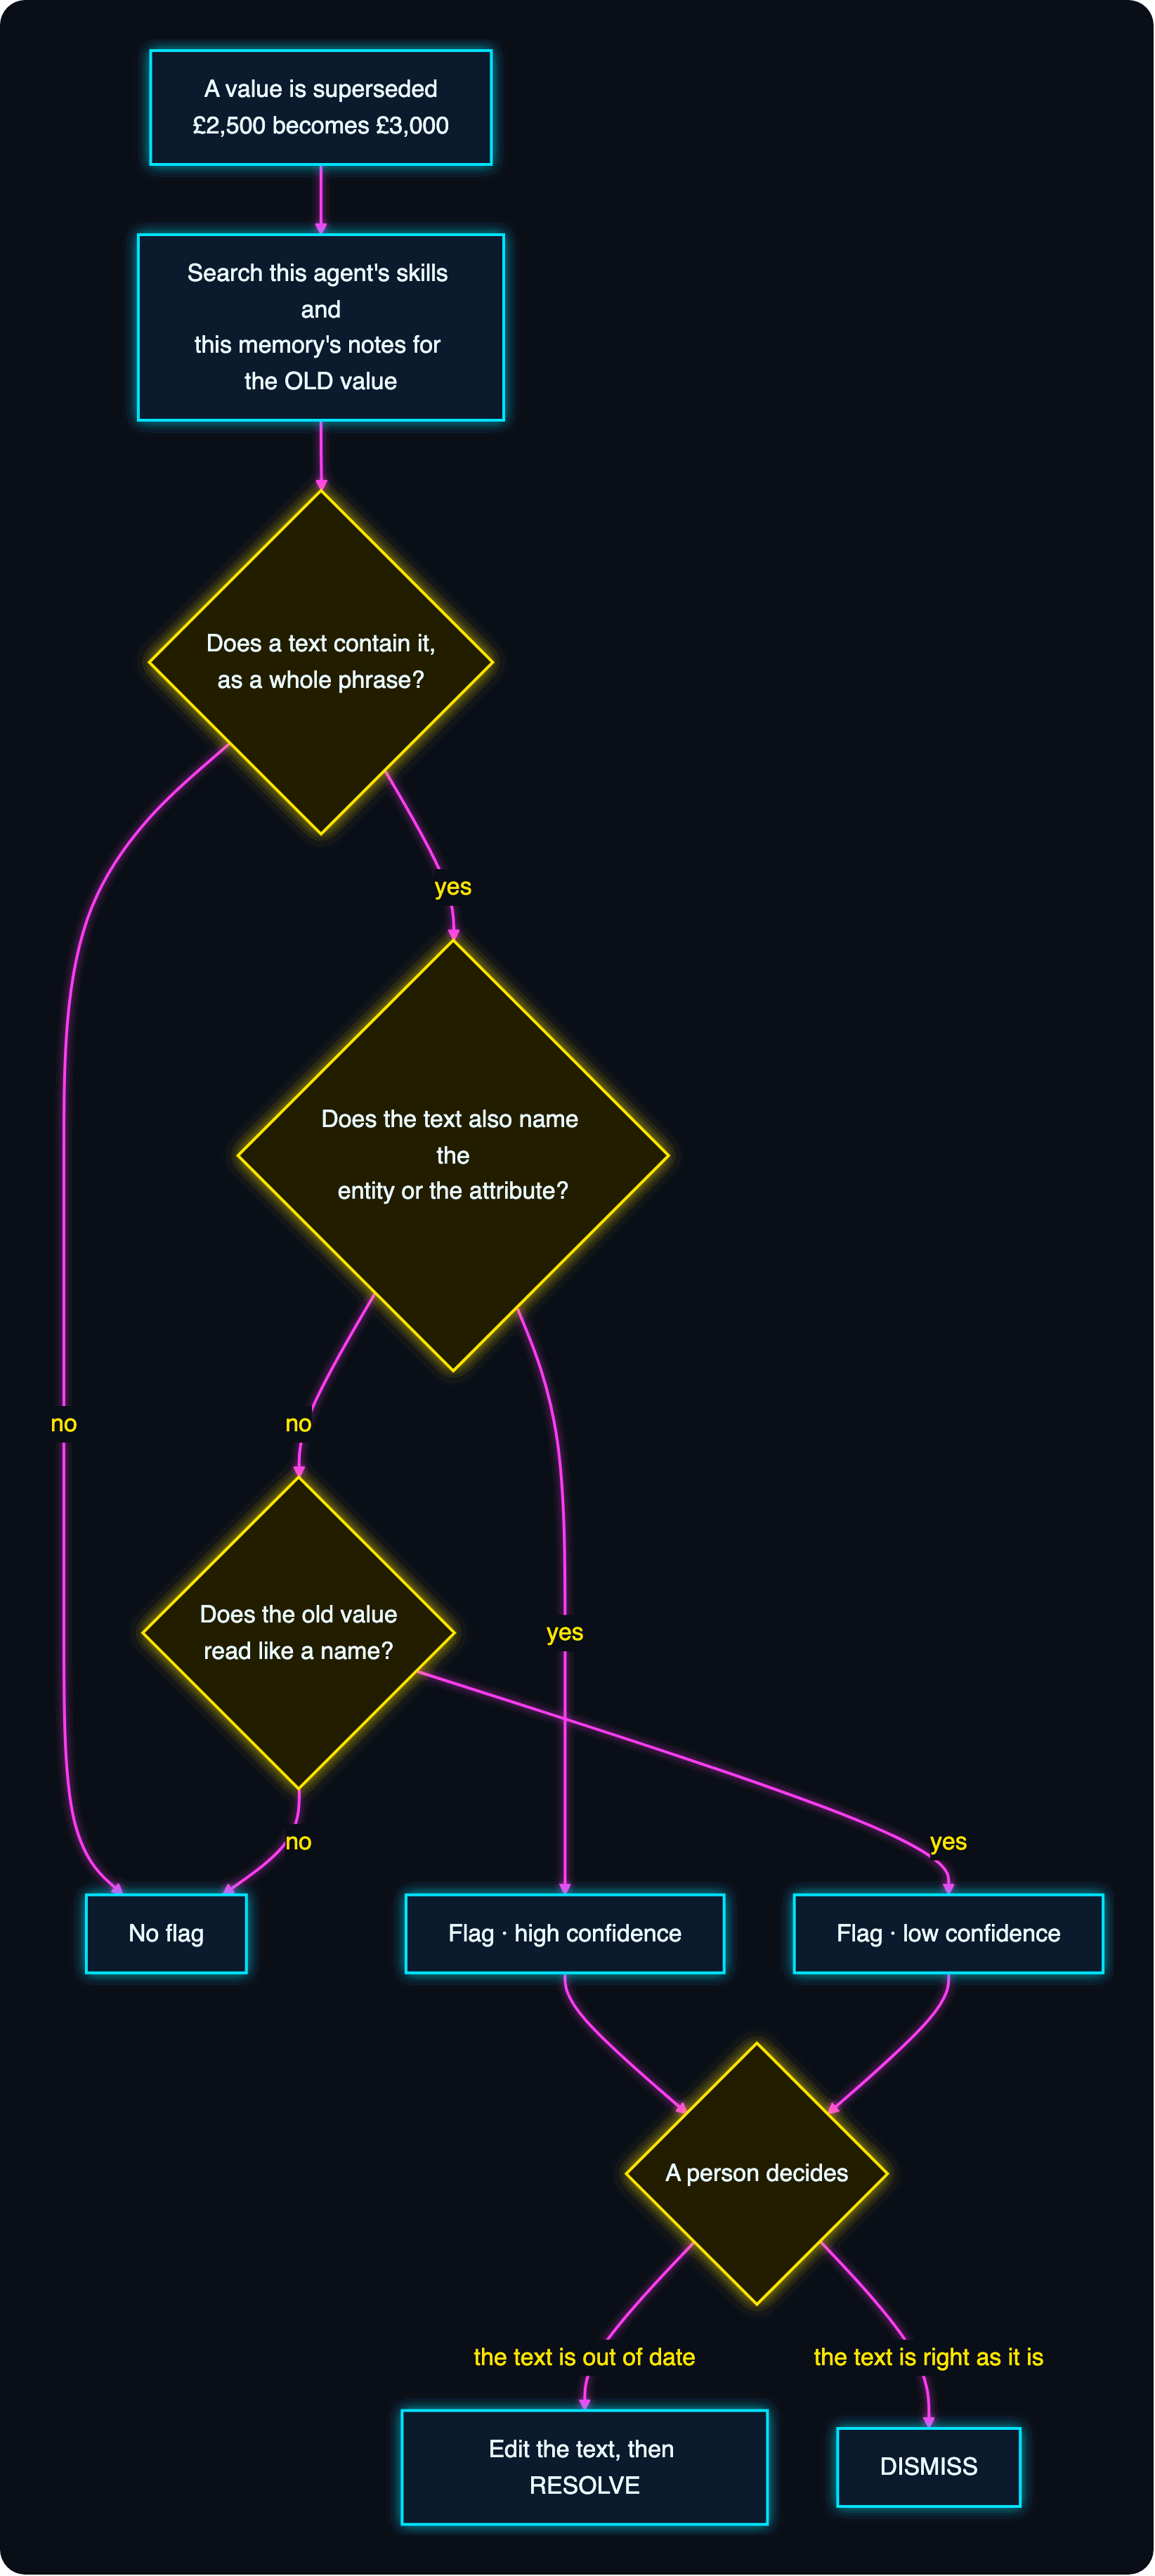

**How to read it.** Start at the top left: a value has just been replaced. The store
searches two places for the *old* value, and each diamond narrows the match.

| Path | When it applies | How it ends |
|---|---|---|
| **No flag** | No skill or note contains the old value as a whole phrase (or the value is under four characters) | Nothing happens |
| **Flag, high confidence** | The text contains the old value *and* names the entity, one of its aliases, or the attribute | A flag a person should act on |
| **Flag, low confidence** | The old value reads like a name ("Leeds", "Nadia Hussain") and appears by itself | A flag a person should glance at; it may be a different Leeds |
| **Resolved** | Someone brings the text up to date, then closes the flag | Closed, with their name |
| **Dismissed** | Someone decides the text was right to say what it says | Closed, with their name; not raised again for that value |

The matching is narrow on purpose. A number or an ordinary phrase is only flagged when
the text also says what it belongs to — "£2,500" in a note about excess waivers is not
a stale payout limit.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ada.stale_references(status="open", memory_id=...)` | MemoRizz API | The agent's stale-reference flags, newest first. `status` is `"open"`, `"resolved"`, `"dismissed"` or `None` for all | The to-do list a supersession leaves behind |
| a flag | MemoRizz API (data shape) | `target_type` (skill or note), `target_name`, the `entity` and `attribute`, `old_value`, `new_value`, `confidence`, an `excerpt` of the text, and `status` | Everything a person needs to decide without opening three pages |
| `show_flags(status)` | notebook helper | Prints the flags, one per text and old value | Our view of the list |

We didn't call anything to make this happen. An agent that serves a memory listens for
supersessions in it, whoever makes the write: a turn, the host, a background pass.

In [31]:
def show_flags(status="open"):
    flags = ada.stale_references(status=status, memory_id=MEMORY_ID)
    print(f"{len(flags)} {status or 'stored'} stale-reference flag(s)")
    for flag in sorted(flags, key=lambda f: (f["target_type"], f["target_name"], str(f["attribute"]))):
        print(f"  [{flag['target_type']}] {flag['target_name'][:50]!r}")
        print(
            f"      still says {flag['entity']}.{flag['attribute']} = {flag['old_value']}"
            f"   (now {flag['new_value']}; confidence {flag['confidence']})"
        )
    return flags


flags = show_flags()
about = lambda start: [flag for flag in flags if flag["target_name"].startswith(start)]
print("\nthe desk note is flagged for the old office:", any("leeds" in str(f["old_value"]).lower() for f in about("Fraud referrals")))
check(f"the audit note is flagged for {GRADE_1}", any(f["old_value"] == GRADE_1 for f in about("Audit note")))
check(f"the shadow skill is flagged for {GRADE_1}", any(f["target_type"] == "skill" and f["old_value"] == GRADE_1 for f in flags))
_ = check(
    "nothing was rewritten: both notes read exactly as they were written",
    {note_row("Fraud referrals")["content"], note_row("Audit note")["content"]} == {DESK_NOTE, AUDIT_NOTE},
)

3 open stale-reference flag(s)
  [note] 'Audit note, September 2026: the Grade 1 TPA was £2'
      still says Total Payout Authority.grade_1 = £2,500   (now £3,000; confidence high)
  [note] 'Fraud referrals: an Amber Pack goes to the Counter'
      still says Counter Fraud Unit.office_location = Leeds office   (now Manchester office; confidence high)
  [skill] 'Check a payment against TPA'
      still says Total Payout Authority.grade_1 = £2,500   (now £3,000; confidence high)

the desk note is flagged for the old office: True
✓ the audit note is flagged for £2,500
✓ the shadow skill is flagged for £2,500
✓ nothing was rewritten: both notes read exactly as they were written


**How to read that.** Each flag is one text and one old value. The two £2,500 flags are
certain, because we wrote both sides: the host's value was `£2,500` and both texts
contain exactly that, next to "Grade 1". The desk note's flag depends on the run — the
old office is whatever capture wrote on Monday ("Leeds office" in most runs), and it is
flagged when the note contains those words.

Three things are worth being exact about.

- **Nothing was edited.** The last check reads both notes back and compares them with
  what we wrote. A flag is a pointer, not a patch. Rewriting a procedure because a
  number moved is a decision, and decisions about procedures belong to a person.
- **A flag can be wrong, and one of these is.** The audit note says the Grade 1 TPA
  *was* £2,500 *in September 2026*. That is true, and will stay true. The matcher
  can't know that; it sees an old value beside the attribute's name. We'll dismiss it
  in Part 5.
- **The skill's flag is the one that would have hurt.** A shadow skill is one click
  from being an instruction. Activated as it stands, it would tell Ada to refer a
  £2,800 payment that Tom is entitled to make — with an instruction's authority,
  against a record that says otherwise. (Notebook 01 has the structural fix: a skill
  that *reads* the limit instead of writing it down can't go stale this way.)

We'll leave all three open for now. Thursday is about to add one more.

# Part 5 · Thursday: consolidation, the pass that tidies what turns leave behind

Per-turn capture is quick and local, and it misses things. In this part you'll run
the background pass that catches up: it plans before it changes anything, quotes the
user for every fact it wants to add, can be edited by a reviewer, and can be undone
whole. By the end you'll have merged a duplicate, picked up three facts that were
never captured, counted one that was said again, proved that no stale value crept back
in, taken the entire pass back and re-applied it — and closed the stale-reference
flags the week left behind.

## 6 · A day with entity memory off

Capture sees one message at a time, so there are two things it can't do well:

1. **Notice duplicates.** "CFU" and "Counter Fraud Unit" are still two records.
2. **Catch what was never captured.** Capture is best-effort. Conversations happen
   while a deployment has entity memory switched off, or on an older agent version,
   or the model just doesn't file something.

To make the second one concrete, Thursday's conversation happens with Ada's entity
memory **switched off**.

**The data:** four lines, all said while nothing is listening.

| Line | Kind | What consolidation should do with it later |
|---|---|---|
| "The CFU is now led by Sam Adeyemi" | A real change, between equals | Add it, replacing Nadia Hussain |
| "Tom ... now works Mondays to Thursdays" | A real change, between equals | Add it, replacing Tuesdays to Fridays |
| "The Grade 1 TPA is £4,000 now" | A confident claim against the handbook | Keep it beside £3,000; never apply it |
| "...the Counter Fraud Unit is definitely in the Manchester office" | A repeat of something memory already holds | Count it: a confirmation, value unchanged |

Ada hears them, replies, and stores none of them as entity facts.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ada.with_entity_memory(False)` / `(True)` | MemoRizz API | Switches an agent's entity memory, and with it capture and the entity lines in the prompt, off or on | Simulates a day when capture didn't happen |

In [32]:
ada.with_entity_memory(False)  # Thursday's deployment has entity memory off
say("thursday", "Nadia Hussain has moved on. The CFU is now led by Sam Adeyemi.")
say("thursday", "Tom Okafor has changed his days: he now works Mondays to Thursdays.")
say("thursday", "Heads up: the Grade 1 TPA is £4,000 now.")
say("thursday", "And I checked with facilities: the Counter Fraud Unit is definitely in the Manchester office.")
ada.with_entity_memory(True)

before_plan = show_entities("before consolidation")
lead = find_attribute(find_entity("Counter Fraud Unit"), "lead", "led", "head")
_ = check(f"the store still says {CFU_LEAD} leads the unit", lead and CFU_LEAD in str(lead["value"]))

Priya: Nadia Hussain has moved on. The CFU is now led by Sam Adeyemi.
Ada:   Noted — Nadia Hussain has moved on, and Sam Adeyemi now leads the Counter Fraud Unit.



Priya: Tom Okafor has changed his days: he now works Mondays to Thursdays.
Ada:   Noted — Tom Okafor now works Mondays to Thursdays.



Priya: Heads up: the Grade 1 TPA is £4,000 now.
Ada:   Thanks for the heads-up. I can’t treat £4,000 as the Grade 1 TPA without confirmation in the policy handbook; the last recorded limit is £2,500.



Priya: And I checked with facilities: the Counter Fraud Unit is definitely in the Manchester office.
Ada:   Noted — the Counter Fraud Unit is in the Manchester office. This updates the earlier Leeds location.

== before consolidation: 7 entities ==
Total Payout Authority [policy]
    L3  grade_1 = £3,000  · 2 earlier
    L3  grade_2 = £10,000
    L3  senior = £50,000  · 1 earlier
Counter Fraud Unit [team]
    L2  lead = Nadia Hussain
    L2  office_location = Manchester office  · 1 earlier
CFU [team]
    L2  lead = Nadia Hussain
Drop [system]
    L2  purpose = customer upload portal for large files  · 1 earlier
    L2  status = retired  · 1 earlier
user [person]
    L2  name = Priya Shah
    L2  grade = Grade 2
    L2  role = handler
    L2  desk = home claims desk
Tom Okafor [person]
    L2  role = Grade 1 handler
    L2  work_schedule = Tuesdays to Fridays
    L2  relationship_to_user = colleague
Compass [system]
    L2  purpose = customer upload portal
    L2  status = in use
✓ the 

Read Ada's replies against the store. She says "understood" — and the records
underneath haven't moved, because on Thursday she had no entity memory to write to.
*A polite acknowledgement is not a write.* Which is exactly why you check the store
and not the transcript.

Look at her answer to the £4,000 line, too. With entity memory off she is, for one
day, her own twin: no record to read, only the conversation so far. If she quotes a
limit back at Priya, check which one. When it is the September figure, that's why:
it is the last number *she herself* said out loud, on Wednesday morning, before the
handbook changed. A transcript remembers what was said. It doesn't know what has
happened since.

The store is now stale in two places and duplicated in one. Time for a pass. This is
its shape:

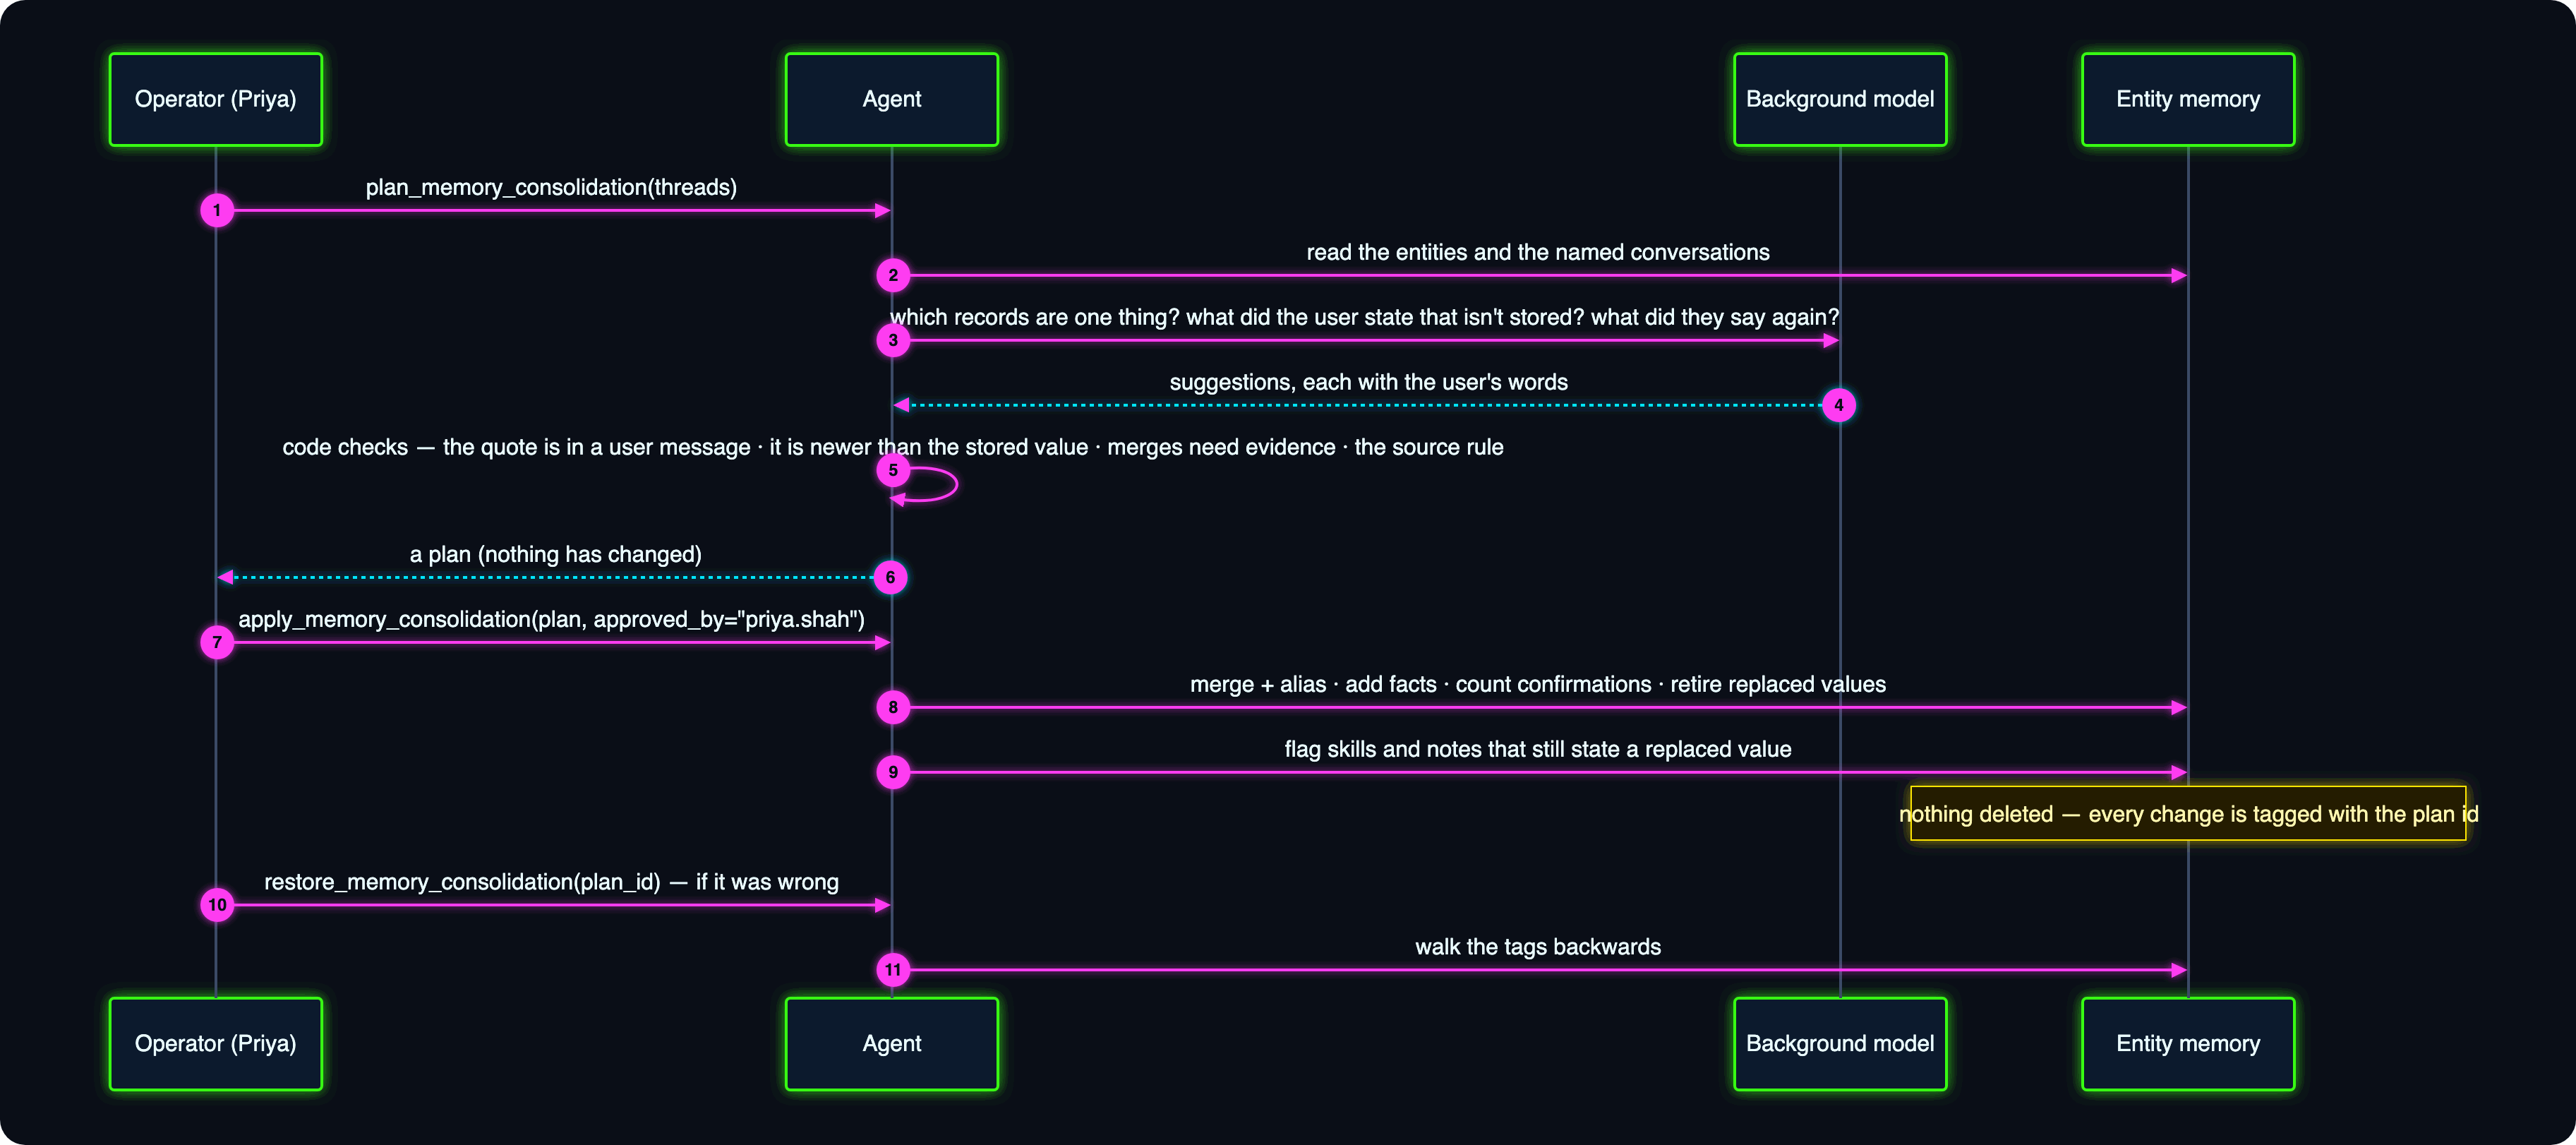

**How to read it.** Time runs downwards, in three acts. Steps 1 to 6 are the **plan**:
the agent reads, the background model suggests, the code checks, and a person gets a
list of proposals with nothing changed. Steps 7 to 9 are the **apply**: with a name on
it, the changes are made, and the texts that still quote a replaced value are flagged.
Steps 10 and 11 are the **undo**, by plan id.

| Kind of operation in a plan | When the pass proposes it | How it ends |
|---|---|---|
| `merge_entities` | Two records are one thing: their names agree and they share a fact | One record; the other name becomes an alias |
| `add_fact` | The user stated something, in words that can be quoted, that memory doesn't hold or holds differently | Written at level 1; replaces a level-1 or level-2 value, is kept *beside* a level-3 one |
| `reinforce_fact` | The user stated, in a later conversation, something memory already holds | One more confirmation. Nothing else moves |
| `retire_attribute` | One fact filed under two attribute names | The older one is retired |

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ada.plan_memory_consolidation(memory_id, user_id=..., thread_ids=...)` | MemoRizz API | A **dry run**: reads the entities and the named conversations, asks the background model what should change, checks its answers in code, returns a plan | Nothing is written; this is the thing a person reviews |
| `plan.plan_id` | MemoRizz API (result) | A fingerprint of the plan's operations | What was approved is exactly what gets applied — and what gets undone |
| `plan.counts` | MemoRizz API (result) | How many operations of each kind the plan holds. `reinforce_fact` is listed when the plan has one | The plan at a glance |

The code checks are the part to trust. Each new fact must quote words that really
appear in one of the user's messages. And a quote only counts if it is **newer than
the value it would replace** — Monday's "sits in Leeds" is a real quote, but memory
moved on from it on Wednesday, so it is history, not news.

In [33]:
plan = ada.plan_memory_consolidation(MEMORY_ID, user_id=USER_ID, thread_ids=THREADS)
held = {record["entity_id"]: record["name"] for record in before_plan}
held_names = {name.casefold().replace("_", " ") for name in held.values()}

print("plan:", plan.plan_id[:24] + "…")
print("counts:", plan.counts)

plan: consolidate-e9cb100e3cb4…
counts: {'merge_entities': 1, 'suppress_duplicate': 0, 'retire_attribute': 0, 'add_fact': 3, 'reinforce_fact': 1}


**Read the plan one operation at a time.** A plan is a list of `ops`, and the next
cell defines a small printer for one of them.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `op.kind` | MemoRizz API (result) | `merge_entities`, `add_fact`, `reinforce_fact`, `retire_attribute` or `suppress_duplicate` | What the operation would do |
| `op.reason` | MemoRizz API (result) | A plain-language reason, written by the code, not the model | The sentence a reviewer reads first |
| `op.target_id` | MemoRizz API (result) | The record the operation would touch (empty for a fact that would start a new record) | Tells you where a fact will land |
| `op.details` | MemoRizz API (result) | For a merge, the `names`; for a fact, `entity`, `attribute`, `value`, what it `replaces`, what it is kept `beside`, and the `evidence` | `beside` is the source rule again: offered next to a host value, never applied |
| `would_duplicate(op)` | notebook helper | Flags a fact that would start a *new* record for something memory already holds under another spelling | Our own reviewer's check, not MemoRizz's |
| `describe(op)` | notebook helper | Prints one operation in the shape above | So the plan reads like a list of proposals |

In [34]:
def would_duplicate(op):
    return (
        op.kind == "add_fact"
        and op.target_id not in held
        and str(op.details.get("entity", "")).casefold().replace("_", " ") in held_names
    )


def describe(op):
    details = op.details
    print(f"[{op.kind}] {op.reason}")
    if op.kind == "merge_entities":
        print("    names:", details.get("names"))
    elif op.kind in ("add_fact", "reinforce_fact"):
        print(f"    {details.get('entity')}.{details.get('attribute')} = {details.get('value')}")
        print("    lands on:", held.get(op.target_id) or f"a NEW record named {details.get('entity')!r}")
        if details.get("replaces") is not None:
            print("    replaces:", details.get("replaces"))
        if details.get("beside") is not None:
            print("    kept beside (not applied):", details.get("beside"))
        if details.get("evidence"):
            print(f"    the user said: \"{details['evidence']}\"")
    print()

**Now the plan itself, and four checks on it.** The first is the definition of a dry
run. The last two are the ones that fail loudly if consolidation ever starts dragging
the past back in: no fact may start a second record for something already held, and
no fact may carry *Leeds*.

In [35]:
for op in plan.ops:
    describe(op)

strays = [op.details.get("entity") for op in plan.ops if would_duplicate(op)]
stale = [op for op in plan.ops if op.kind == "add_fact" and "leeds" in str(op.details.get("value")).lower()]
restated = [op for op in plan.ops if op.kind == "reinforce_fact"]
print("facts the plan would confirm rather than add:", [f"{op.details['entity']}.{op.details['attribute']}" for op in restated])
check("nothing changed yet (a plan is a dry run)", len(entities.list_entities(**SCOPE)) == len(before_plan))
check("the plan merges the duplicate", plan.counts.get("merge_entities", 0) >= 1)
check("the plan adds facts stated on Thursday", plan.counts.get("add_fact", 0) >= 1)
check("no fact would start a second record for something already held", not strays)
_ = check("no fact brings Leeds back", not stale)

[merge_entities] one entity under 2 names, sharing 1 fact and a matching name
    names: ['Counter Fraud Unit', 'CFU']

[add_fact] the user said this; memory still had the old value
    counter fraud unit.lead = Sam Adeyemi
    lands on: Counter Fraud Unit
    replaces: Nadia Hussain
    the user said: "The CFU is now led by Sam Adeyemi."

[add_fact] the user said this; memory still had the old value
    tom okafor.work_schedule = Mondays to Thursdays
    lands on: Tom Okafor
    replaces: Tuesdays to Fridays
    the user said: "he now works Mondays to Thursdays."

[add_fact] the user said this; the stored value came from the host application, so it stays and this is kept beside it
    total payout authority.grade_1 = £4,000
    lands on: Total Payout Authority
    kept beside (not applied): £3,000
    the user said: "the Grade 1 TPA is £4,000 now."

[reinforce_fact] the user said this again; memory already holds it
    Counter Fraud Unit.office_location = Manchester office
    lands o

**Read the plan the way a reviewer would.** That's what it's for.

- The **merge** rests on the two names agreeing ("CFU" is the initials of "Counter
  Fraud Unit") *and* a shared fact. A name match alone is not enough to fold two
  records together.
- Each **`add_fact`** shows the sentence it came from, and `lands on` says which
  existing record it will be written to. Notice how the model spells entities —
  `tom_okafor`, `total_payout_authority`, sometimes `counter_fraud_unit` and sometimes
  `cfu` — and that each still lands on a record memory already holds. The code
  resolves the spelling; it doesn't trust it.
- Find the **£4,000** claim. Priya said it plainly this time, and the model duly
  proposed it. But the handbook's limit is level 3, so the most a background pass can
  do is keep it *beside* the value. The source rule doesn't get a day off because the
  writer is a background job.
- Look for a **`reinforce_fact`**. Priya's fourth line said nothing new: memory has
  held "Manchester office" since Wednesday. The pass still read it, and proposes the
  one thing a repeat deserves — a confirmation. (It is a model's reading of a
  transcript, so on some runs it won't be there. The printed list above says whether
  it is.) Note what earns it: the statement has to be *later* than the stored value.
  Wednesday's own "moved to the Manchester office" is where the value came from, not a
  confirmation of it.
- And notice what is **not** there: Monday's and Tuesday's "Leeds". Both are genuine
  quotes from Priya, in conversations the pass was told to read. Both are older than
  the value memory holds now. An older statement is not an update.

(You may see the same fact proposed for each of the two records that are about to
become one. The plan is drawn up before the merge happens; the survivor gets the fact
once.)

### A plan is a proposal — so review it

A reviewer doesn't have to take a plan whole. The next cell strikes any line that
`would_duplicate` flagged and keeps the rest. In most runs that is nothing — but a
small model will occasionally invent a name, and a duplicate record quietly splits
everything that is learned afterwards.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ConsolidationPlan(...)` | MemoRizz API | A plan is a plain value: a memory, a user and a tuple of operations | You can build a reviewed plan from the operations you kept |
| `ConsolidationPlan.make_id(memory_id, user_id, ops)` | MemoRizz API | Computes the fingerprint for a set of operations | An edited plan gets a new id; one tampered with after approval is refused |

Striking a line has a cost: the fact it carried is not written by this pass. A check
further down would show a cross for it.

In [36]:
from memorizz.learning.consolidation import ConsolidationPlan

kept = tuple(op for op in plan.ops if not would_duplicate(op))
struck = len(plan.ops) - len(kept)
if struck:
    plan = ConsolidationPlan(
        plan_id=ConsolidationPlan.make_id(MEMORY_ID, USER_ID, kept),
        memory_id=MEMORY_ID,
        user_id=USER_ID,
        ops=kept,
        model=plan.model,
        warnings=plan.warnings,
    )
print(f"struck {struck} operation(s); the plan to approve has {len(plan.ops)}: {plan.counts}")
print("plan:", plan.plan_id[:24] + "…")

struck 0 operation(s); the plan to approve has 5: {'merge_entities': 1, 'suppress_duplicate': 0, 'retire_attribute': 0, 'add_fact': 3, 'reinforce_fact': 1}
plan: consolidate-e9cb100e3cb4…


### Apply it, with a name

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ada.apply_memory_consolidation(plan, approved_by=...)` | MemoRizz API | Makes the plan's changes. `approved_by` is required and is recorded on every change | Nothing a background pass proposes is applied anonymously |
| `result.applied` | MemoRizz API (result) | Counts of what was done, including `fact_not_applied` (facts kept beside a stronger value) and `reinforce_fact` (confirmations counted) | Says at once whether the source rule turned anything down |
| `result.errors` | MemoRizz API (result) | Operations that could not be applied, with the reason | Should be empty |

In [37]:
result = ada.apply_memory_consolidation(plan, approved_by=USER_ID)
print("applied:", result.applied)
for error in result.errors:
    print("not applied:", error)
print()
after_apply = show_entities("after consolidation")

applied: {'merge_entities': 1, 'suppress_duplicate': 0, 'retire_attribute': 0, 'add_fact': 2, 'reinforce_fact': 1, 'fact_not_applied': 1}

== after consolidation: 6 entities ==
Total Payout Authority [policy]
    L3  grade_1 = £3,000  · 3 earlier
    L3  grade_2 = £10,000
    L3  senior = £50,000  · 1 earlier
Counter Fraud Unit [team]  (also known as: CFU)
    L2  office_location = Manchester office  · 1 earlier
    L1  lead = Sam Adeyemi
Drop [system]
    L2  purpose = customer upload portal for large files  · 1 earlier
    L2  status = retired  · 1 earlier
user [person]
    L2  name = Priya Shah
    L2  grade = Grade 2
    L2  role = handler
    L2  desk = home claims desk
Tom Okafor [person]
    L2  role = Grade 1 handler
    L2  relationship_to_user = colleague
    L1  work_schedule = Mondays to Thursdays
Compass [system]
    L2  purpose = customer upload portal
    L2  status = in use


**First, the merge.** The result above says what was applied. These checks say whether
it's *right*: the duplicate gone, and its name kept so that the next message that says
"CFU" finds the right record.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `entity_aliases(record)` | MemoRizz API | The other names a record answers to | A merge keeps the losing name as an alias |
| `entities.get_entity_by_alias(name, ...)` | MemoRizz API | Finds a live record by one of its aliases | Proves "CFU" still resolves |

In [38]:
live_names = {record["name"] for record in after_apply}
unit = find_entity("Counter Fraud Unit")
via_alias = entities.get_entity_by_alias("CFU", **SCOPE)

check("the duplicate is gone: 'CFU' is no longer a record of its own", "CFU" not in live_names)
check("'CFU' is now an alias of the surviving record", "CFU" in entity_aliases(unit))
_ = check("a lookup by the alias resolves to it", bool(via_alias) and via_alias["name"] == unit["name"])

✓ the duplicate is gone: 'CFU' is no longer a record of its own
✓ 'CFU' is now an alias of the surviving record
✓ a lookup by the alias resolves to it


**Then the confirmation.** If the plan held a `reinforce_fact`, the office now carries
it. Nothing new to learn in the code: the same three fields as Tuesday
(`confirmations`, `last_seen`, `confirmed_by`), read off the record. This time the
source is the plan itself, and the conversation it came from is Thursday's.

In [39]:
office = find_attribute(unit, "location", "office", "site", "based")
show_timeline(unit, office)
print("confirmations:", office.get("confirmations", 0), "| last seen:", when(office.get("last_seen")))
for item in office.get("confirmed_by") or []:
    print("   confirmed by", str(item.get("source"))[:38] + "…", "from the conversation", item.get("thread_id"))
if restated:
    check("the restated office gained a confirmation", office.get("confirmations", 0) >= 1)
    _ = check("and kept its value", "manchester" in str(office["value"]).lower())
else:
    print("(this run's plan had no reinforce_fact, so there is nothing to count)")

Counter Fraud Unit · office_location
    L2  Manchester office    current since 2026-11-12 15:37 · confirmed 1×        source: entity_capture
    L2  Leeds office         was current 2026-11-12 15:36 → 2026-11-12 15:37 · confirmed 1× source: User stated that the Counter
confirmations: 1 | last seen: 2026-11-12 15:38
   confirmed by consolidation:consolidate-e9cb100e3cb4… from the conversation thursday-cf6f8f
✓ the restated office gained a confirmation
✓ and kept its value


**Then every value this week superseded.** This is the check that matters most, and
the one an earlier version of this notebook didn't have. A pass that reads old
conversations is one bug away from re-learning the past: Monday's "Leeds" is right
there in the transcript, perfectly quotable.

So for each fact that changed this week we assert three things: the current value is
the new one; the old value is **not current anywhere on the record** (not even under
some other attribute name the model made up); and the old value is still *kept* —
dated in a history or retired by the pass. Miss any of the three and a cross prints.

**The data: `SUPERSEDED`, the truth of the week.** Five rows, one for each fact that
changed between Monday and Thursday. It is the answer key, written by us, not read
from the store.

| Field of a row | In the example row | Meaning |
|---|---|---|
| label | `"the unit's office"` | What to call the fact in the output |
| record | `"Counter Fraud Unit"` | Which entity holds it |
| words | `("location", "office", "site", "based")` | Any of these in an attribute's name identifies the attribute (the model picks the exact name) |
| new | `"manchester"` | A word the **current** value must contain |
| old | `"leeds"` | A word that must **not** be current anywhere on the record, and must still be kept in history |

| The five rows | Changed by | On |
|---|---|---|
| The unit's office: Leeds → Manchester | Priya, in conversation | Wednesday |
| The unit's lead: Nadia → Sam Adeyemi | Consolidation, from Thursday's transcript | Thursday |
| Tom's days: …Fridays → Mondays to Thursdays | Consolidation, from Thursday's transcript | Thursday |
| Drop's status: in use → retired | Priya, in conversation | Wednesday |
| The Grade 1 limit: £2,500 → £3,000 | The application | Wednesday |

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `SUPERSEDED` | notebook helper (data) | One row per changed fact: the record, a word that finds the attribute, a word the current value must contain, and the old value's word | The truth of the week, written down once |
| `still_current(record, old)` | notebook helper | Does any attribute of the record still offer the old value as current? (Attributes that are plainly about the past, like `office_move`, are skipped; Drop's status is matched exactly, so "no longer in use" isn't "in use") | Catches the old value resurfacing under a new attribute name |
| `kept_somewhere(record, old)` | notebook helper | Is the old value in an attribute's history, or among the record's retired attributes? | "Supersede, don't delete", as a test |
| `check_superseded()` | notebook helper | Runs the three assertions for every row | We'll call it again after undoing and re-applying the pass |

In [40]:
SUPERSEDED = [
    ("the unit's office", "Counter Fraud Unit", ("location", "office", "site", "based"), "manchester", "leeds"),
    ("the unit's lead", "Counter Fraud Unit", ("lead", "led", "head"), "sam adeyemi", "nadia"),
    ("Tom's days", "Tom Okafor", ("day", "schedule"), "monday", "friday"),
    ("Drop's status", "Drop", ("status",), "retired", "in use"),
    ("the Grade 1 limit", "Total Payout Authority", ("grade_1",), "3,000", "2,500"),
]


PAST_NAMES = ("previous", "former", "old", "move", "replac", "history")  # attributes that are about the past


def still_current(record, old):
    """Is the old value offered as current by any attribute of the record?"""
    live = [a for a in record.get("attributes") or [] if not any(w in a["name"].lower() for w in PAST_NAMES)]
    values = [str(a.get("value")).lower().strip() for a in live]
    return old in values if old == "in use" else any(old in value for value in values)


def kept_somewhere(record, old):
    """The old value is still held: in an attribute's history, or retired by a pass."""
    past = [row.get("value") for a in record.get("attributes") or [] for row in attribute_timeline(a)[1:]]
    past += [item.get("value") for item in (record.get("metadata") or {}).get("retired_attributes") or []]
    return any(old in str(value).lower() for value in past)

**And the function that runs it.** One line of output per fact, a tick only when all
three assertions hold. The middle one is the bug-catcher: a stray
`location = Leeds office` beside `office_location = Manchester office` would fail it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `check_superseded()` | Notebook helper | For every fact in `SUPERSEDED`, asserts three things: the new value is current, the old value is not current anywhere on the record, and the old value is still kept in history or the retired shelf | One visible tick or cross per superseded fact, so a regression (an old value coming back) can't pass unnoticed |

In [41]:
def check_superseded():
    passed = True
    for label, name, words, new, old in SUPERSEDED:
        record = find_entity(name) or {}
        attribute = find_attribute(record, *words) or {}
        ok = (
            new in str(attribute.get("value")).lower()
            and not still_current(record, old)
            and kept_somewhere(record, old)
        )
        passed &= check(f"{label}: now {attribute.get('value')!r}; {old!r} is kept but no longer current", ok)
    return passed


all_superseded = check_superseded()

✓ the unit's office: now 'Manchester office'; 'leeds' is kept but no longer current
✓ the unit's lead: now 'Sam Adeyemi'; 'nadia' is kept but no longer current
✓ Tom's days: now 'Mondays to Thursdays'; 'friday' is kept but no longer current
✓ Drop's status: now 'retired'; 'in use' is kept but no longer current
✓ the Grade 1 limit: now '£3,000'; '2,500' is kept but no longer current


Five ticks is the result this notebook exists to produce. If you ever see a cross
here, *stop and read the plan again* — a cross means the store now disagrees with the
week as it happened, and every answer downstream inherits that.

The Grade 1 limit deserves a closer look, because it has now been challenged twice by
weaker sources: Wednesday's rumour and Thursday's confident claim.

In [42]:
tpa = find_entity("Total Payout Authority")
limit = find_attribute(tpa, "grade_1")
offers = [row for row in attribute_timeline(limit) if not row["applied"]]
show_timeline(tpa, limit)
print()
check("the handbook's limit survived the pass", limit["value"] == GRADE_1_NEW)
check("£3,500 is on the record as offered, not applied", any("3,500" in str(row.get("value")) for row in offers))
_ = check("£4,000 is on the record as offered, not applied", any("4,000" in str(row.get("value")) for row in offers))

Total Payout Authority · grade_1
    L3  £3,000               current since 2027-01-04 00:00                       source: policy_handbook
    L1  £4,000               offered 2026-11-12 15:38, NOT applied                source: consolidation:consolidate-e9
    L3  £2,500               was current 2026-09-01 00:00 → 2027-01-04 00:00      source: policy_handbook
    L2  £3,500               offered 2026-11-12 15:37, NOT applied                source: conversation

✓ the handbook's limit survived the pass
✓ £3,500 is on the record as offered, not applied
✓ £4,000 is on the record as offered, not applied


Four values, one current. The September figure with the dates it held, and two
figures that were only ever somebody's say-so — one written at level 2 from the
conversation, one at level 1 by the pass — both refused, both kept.

**And the history behind the unit's new lead.** A consolidation pass retires; it
doesn't delete.

In [43]:
lead = find_attribute(unit, "lead", "led", "head")
if lead:
    show_timeline(unit, lead)
for record in (unit, find_entity("Tom Okafor")):
    print(f"{record['name']} · retired by the pass")
    show_retired(record)

Counter Fraud Unit · lead
    L1  Sam Adeyemi          current since 2026-11-12 15:38                       source: consolidation:consolidate-e9
Counter Fraud Unit · retired by the pass
    retired  lead = Nadia Hussain  (was L2, retired 2026-11-12 15:38 by consolidate-e9cb100e3cb4…)
Tom Okafor · retired by the pass
    retired  work_schedule = Tuesdays to Fridays  (was L2, retired 2026-11-12 15:38 by consolidate-e9cb100e3cb4…)


Three things to notice.

The **alias** is what makes a merge safe. The short name didn't disappear; it became
another name the surviving record answers to, so the next message that says "CFU"
lands on the right record instead of quietly recreating the duplicate.

The **new lead replaced the old one** even though consolidation writes at the lowest
level. That's a deliberate exception: a fact that *quotes the user* carries the user's
authority for values at levels 1 and 2. It still can't touch level 3, as the limit's
timeline shows. (This is one reading of the rule — a stricter one would never let a
consolidated fact replace a user-stated value. It's a judgement call, and the stricter
reading is defensible.)

And Nadia Hussain is still on the record. A value that consolidation replaces is
**retired** rather than dated into the attribute's own history: it moves to the
entity's `metadata.retired_attributes` with who retired it and when, where no prompt
or search reads it. (Two shelves for old values, then — history for turn-by-turn
changes, retirement for a pass's changes. The second is what lets a whole plan be
undone in one call.)

### Undo is a first-class operation

"Nothing is deleted" is easy to claim. Here is what it buys you: the whole plan can be
taken back, by its id.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ada.restore_memory_consolidation(plan_id, approved_by=..., memory_id=..., user_id=...)` | MemoRizz API | Undoes every change a plan made: merged records come back, aliases are removed, added facts are taken out, retired values return | A wrong pass becomes an inconvenience, not an incident |

In [44]:
restored = ada.restore_memory_consolidation(plan.plan_id, approved_by=USER_ID, **SCOPE)
print("restored:", restored, "\n")

after_restore = show_entities("after restore")
full = entities.get_entity_by_name("Counter Fraud Unit", **SCOPE)
lead = find_attribute(full, "lead", "led", "head")
print()
check("the 'CFU' record is back", "CFU" in {record["name"] for record in after_restore})
check("the alias went with the merge", "CFU" not in entity_aliases(full))
check(f"the lead is back to {CFU_LEAD}", lead and CFU_LEAD in str(lead["value"]))
office = find_attribute(full, "location", "office", "site", "based")
_ = check("the pass's confirmation went with it", not office.get("confirmations"))

restored: {'entities': 1, 'attributes': 1, 'facts_removed': 1, 'rows': 0} 

== after restore: 7 entities ==
Total Payout Authority [policy]
    L3  grade_1 = £3,000  · 3 earlier
    L3  grade_2 = £10,000
    L3  senior = £50,000  · 1 earlier
Counter Fraud Unit [team]
    L2  lead = Nadia Hussain
    L2  office_location = Manchester office  · 1 earlier
CFU [team]
    L2  lead = Nadia Hussain
Drop [system]
    L2  purpose = customer upload portal for large files  · 1 earlier
    L2  status = retired  · 1 earlier
user [person]
    L2  name = Priya Shah
    L2  grade = Grade 2
    L2  role = handler
    L2  desk = home claims desk
Tom Okafor [person]
    L2  role = Grade 1 handler
    L2  relationship_to_user = colleague
    L2  work_schedule = Tuesdays to Fridays
Compass [system]
    L2  purpose = customer upload portal
    L2  status = in use

✓ the 'CFU' record is back
✓ the alias went with the merge
✓ the lead is back to Nadia Hussain
✓ the pass's confirmation went with it


Merged records get a `superseded_by` pointer rather than a delete; retired attributes
move to the entity's metadata; added facts and confirmations are tagged with the plan
that made them. Restoring walks those markers backwards.

The plan was right, though, so we apply it again — and run the superseded-value checks
a second time, because "apply, undo, apply" is exactly the kind of sequence that
shakes loose an ordering bug.

In [45]:
result = ada.apply_memory_consolidation(plan, approved_by=USER_ID)
print("re-applied:", result.applied)
final = show_entities("final state")
print()
check("consolidated again", "CFU" not in {record["name"] for record in final})
_ = check("and every superseded value is still right", check_superseded())

re-applied: {'merge_entities': 1, 'suppress_duplicate': 0, 'retire_attribute': 0, 'add_fact': 2, 'reinforce_fact': 1, 'fact_not_applied': 1}
== final state: 6 entities ==
Total Payout Authority [policy]
    L3  grade_1 = £3,000  · 3 earlier
    L3  grade_2 = £10,000
    L3  senior = £50,000  · 1 earlier
Counter Fraud Unit [team]  (also known as: CFU)
    L2  office_location = Manchester office  · 1 earlier
    L1  lead = Sam Adeyemi
Drop [system]
    L2  purpose = customer upload portal for large files  · 1 earlier
    L2  status = retired  · 1 earlier
user [person]
    L2  name = Priya Shah
    L2  grade = Grade 2
    L2  role = handler
    L2  desk = home claims desk
Tom Okafor [person]
    L2  role = Grade 1 handler
    L2  relationship_to_user = colleague
    L1  work_schedule = Mondays to Thursdays
Compass [system]
    L2  purpose = customer upload portal
    L2  status = in use

✓ consolidated again
✓ the unit's office: now 'Manchester office'; 'leeds' is kept but no longer curre

This is the pass as the MemoRizz UI shows it. Because we switched write history on at
the start, the *Learning control plane* lists the plan under **Applied plans**: its
id, the memory, how many changes were recorded, who approved it and when. The last
column is where a plan is undone from the UI — the button form of
`restore_memory_consolidation`. (Ours reads *Undone* because we did exactly that a
moment ago before applying it again.)

![The Learning control plane's Memory consolidation section listing the applied plan with its approver and an Undo control](images/03_applied_plans.png)

### Closing the loop: the flags the week left behind

At the end of Part 4 three texts were flagged for quoting old values. The pass has
since changed the fraud team's lead, and the desk note names the old one. So the list
should have grown by itself.

Nothing new in this cell: `show_flags` from Part 4.

In [46]:
flags = show_flags()
print()
_ = check(
    f"the pass's change raised a flag too: the desk note still names {CFU_LEAD}",
    any(CFU_LEAD in str(flag["old_value"]) and flag["target_name"].startswith("Fraud referrals") for flag in flags),
)

4 open stale-reference flag(s)
  [note] 'Audit note, September 2026: the Grade 1 TPA was £2'
      still says Total Payout Authority.grade_1 = £2,500   (now £3,000; confidence high)
  [note] 'Fraud referrals: an Amber Pack goes to the Counter'
      still says Counter Fraud Unit.lead = Nadia Hussain   (now Sam Adeyemi; confidence high)
  [note] 'Fraud referrals: an Amber Pack goes to the Counter'
      still says Counter Fraud Unit.office_location = Leeds office   (now Manchester office; confidence high)
  [skill] 'Check a payment against TPA'
      still says Total Payout Authority.grade_1 = £2,500   (now £3,000; confidence high)

✓ the pass's change raised a flag too: the desk note still names Nadia Hussain


A flag exists to be closed by a person, and there are two honest ways to close one.

| The text | What a person decides | What they do |
|---|---|---|
| **The desk note** (Leeds, Nadia Hussain) | It is simply out of date | Edit the note, then **resolve** its flags |
| **The audit note** (£2,500 in September 2026) | It is a dated record of the past. It *should* say £2,500 | **Dismiss** the flag. It won't be raised again for that value |
| **The shadow skill** (£2,500 as the limit) | Not decided yet: fix the number, or rewrite the step to read the limit? | Leave it **open** |

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `provider.update_by_id(id, {"content": ...}, MemoryType.KNOWLEDGE_BASE)` | MemoRizz API | Rewrites one stored note | The person's edit. MemoRizz didn't make it |
| `ada.resolve_stale_reference(flag_id, by=..., note=...)` | MemoRizz API | Closes a flag because the text was brought up to date. A name is required | "Fixed" |
| `ada.dismiss_stale_reference(flag_id, by=..., note=...)` | MemoRizz API | Closes a flag because the text was not wrong. The same text is not flagged again for the same old value | "Not a problem" |

The name on both is Dev, the Desk Lead.

In [47]:
desk = note_row("Fraud referrals")
fixed = DESK_NOTE.replace("Leeds office", "Manchester office").replace(CFU_LEAD, "Sam Adeyemi")
provider.update_by_id(desk["_id"], {"content": fixed}, MemoryType.KNOWLEDGE_BASE)

for flag in ada.stale_references(memory_id=MEMORY_ID):
    if flag["target_name"].startswith("Fraud referrals"):
        ada.resolve_stale_reference(flag["flag_id"], by="dev", note="note brought up to date")
    elif flag["target_name"].startswith("Audit note"):
        ada.dismiss_stale_reference(flag["flag_id"], by="dev", note="a dated record: £2,500 is right for September 2026")

still_open = show_flags()
closed = [flag for flag in ada.stale_references(status=None, memory_id=MEMORY_ID) if flag["status"] != "open"]
print("closed:", sorted((flag["status"], flag["target_name"][:16], str(flag["old_value"])) for flag in closed))
check("the desk note now reads Manchester and Sam Adeyemi", note_row("Fraud referrals")["content"] == fixed)
check("the audit note still says what it said", note_row("Audit note")["content"] == AUDIT_NOTE)
_ = check("only the shadow skill is still waiting", [flag["target_type"] for flag in still_open] == ["skill"])

1 open stale-reference flag(s)
  [skill] 'Check a payment against TPA'
      still says Total Payout Authority.grade_1 = £2,500   (now £3,000; confidence high)
closed: [('dismissed', 'Audit note, Sept', '£2,500'), ('resolved', 'Fraud referrals:', 'Leeds office'), ('resolved', 'Fraud referrals:', 'Nadia Hussain')]
✓ the desk note now reads Manchester and Sam Adeyemi
✓ the audit note still says what it said
✓ only the shadow skill is still waiting


One flag left, on purpose. It is the honest state of things: nobody has yet decided
what to do with a draft procedure that hard-codes a limit. An open flag is how that
undecided question stays visible instead of being forgotten.

That's the whole path a change takes, then. The record is superseded, with both
clocks. The prompt gets the new value on the next turn. And the texts that copied the
old one are found and put in front of a person — *propagation* — without a single
character of them being changed by the machine.

# Part 6 · Friday: the same questions, to both agents

Everything so far has been about the store. This part is about whether any of it
changes an answer. You'll ask Ada and her twin five questions — a decision, a current
figure, a figure from the past, a retired system and a renamed team — grade both with
a deliberately crude grader, and read the scoreboard for what it does and doesn't
prove. By the end you'll know which kinds of question a transcript can carry and which
need a record.

## 7 · Five questions

A fresh conversation. Both agents sat through the same week, word for word. Both still
have their conversation memory. The difference is what else they were handed:

| | Ada | The twin |
|---|---|---|
| Chat model and instruction | the same | the same |
| The week's conversations | heard them | heard them |
| What the host knows | written to entity memory, and **updated there** | a sentence in her instruction, **as it was before Monday** |
| Entity memory | on: current values under a source rule, history behind a tool | off |
| The two notes | in her memory (the desk note brought up to date in Part 5) | not given: with no entity memory, nothing of hers could be flagged or fixed |

**The data: `QUESTIONS`, the exam.** Five questions, asked of both agents in one new
conversation. We don't take the truth from either agent — we wrote the week ourselves,
so we know it. Each question is a row of three things:

| Field of a row | In the example row | Meaning |
|---|---|---|
| the question | `"Who leads the fraud team, and where are they?"` | What Priya types on Friday |
| right | `["sam", "manchester"]` | Words a correct answer must **all** contain |
| stale | `["nadia", "leeds"]` | Superseded or rumoured values. Offering any of these as current is a wrong answer |

| Question | What kind it is | Right answer | Why it is hard |
|---|---|---|---|
| Grade 1 TPA today | A current figure | £3,000 | Nobody ever *said* £3,000. It arrived as a write from the application |
| Grade 1 TPA in September 2026 | A **point-in-time** question | £2,500 | The right answer is the *old* value |
| Where to upload a 40MB video | A retired system | Compass | Drop was true for months |
| Who leads the fraud team, and where | A renamed team, two changed facts | Sam Adeyemi, Manchester | "The fraud team" is a name nobody has used all week |
| Can Tom pay £2,800 himself? | A **decision** | Yes | Needs two facts from two sources, and the right one of four figures |

A little more on three of them:

- the one that matters is last: *can Tom pay £2,800 himself?* It needs two facts from
  two sources — Tom is Grade 1 (Priya, Monday) and Grade 1 means £3,000 (the handbook,
  Wednesday);
- the second is a **point-in-time** question. Its right answer is the *old* limit;
- the fourth says "the fraud team", a name nobody has used all week.

In [48]:
# (question, a right answer contains all of these, stale or rumoured values)
QUESTIONS = [
    ("What's a Grade 1 handler's TPA today?", ["3,000"], ["2,500", "3,500", "4,000"]),
    ("What was the Grade 1 TPA in September 2026?", ["2,500"], ["3,500", "4,000"]),
    ("A customer wants to send a 40MB video. Where do they upload it?", ["compass"], ["drop"]),
    ("Who leads the fraud team, and where are they?", ["sam", "manchester"], ["nadia", "leeds"]),
    (
        "Tom Okafor wants to pay £2,800 on CW-512904. Can he do it himself? "
        "Start with Yes or No.",
        ["yes"],
        ["no"],
    ),
]

**A grader that can't be charmed.** It is string matching, on purpose, in two small
pieces. The first deals with a wrinkle: a good answer often *mentions* the old value
in order to dismiss it ("Compass — Drop has been retired"). That isn't a stale answer,
so a mention only counts if the answer offers the value as current.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `says_now(text, word)` | notebook helper | True if the answer offers `word` as a current value: at least one mention that isn't introduced by "not / instead of / moved from…" or followed, in the same breath, by "…has been retired / has moved on" | Stops "Drop has been retired" being marked as "said Drop" |

In [49]:
import re

DISMISSED = re.compile(r"(not|no longer|instead of|rather than|moved from|formerly|previously|replaced)\s+(the\s+|in\s+)?$")
RETIRED = re.compile(r"^(\s+\w+){0,2}?\s+((has|have) been |is |was |has |have )?(retired|moved on|left|gone|replaced|no longer)")


def says_now(text, word):
    """Does the answer offer `word` as a current value, rather than mention it as the past?"""
    for match in re.finditer(re.escape(word), text):
        before, after = text[: match.start()], text[match.end() :]
        if not DISMISSED.search(before) and not RETIRED.match(after):
            return True
    return False

**Then the grades.** An answer is *correct* if it offers every right value and none of
the stale ones; *hedged* if it offers both; *stale or rumour* if it only has an old
one. The yes/no question is stricter: a "yes" has to rest on the right limit. Right
for the wrong reason (yes, because someone said £4,000) gets its own grade — it is the
answer that will be wrong next month.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `grade(answer, right, stale)` | notebook helper | Marks one answer against the truth | Crude checks can't be talked round |

In [50]:
def grade(answer, right, stale):
    text = re.sub(r"[*_`]", "", answer.lower())  # models like to put the answer in bold
    if right == ["yes"]:
        start = text.lstrip()
        if start.startswith("yes"):
            return "correct" if "3,000" in text else "right answer, wrong limit"
        return "wrong" if start.startswith("no") else "unclear"
    has_right = all(says_now(text, word) for word in right)
    has_stale = any(says_now(text, word) for word in stale)
    if has_right and not has_stale:
        return "correct"
    if has_right:
        return "hedged (current and stale)"
    return "stale or rumour" if has_stale else "no right answer"

**Ask both.** Same five questions, same Friday thread, Ada and her twin. The last line
prints `HISTORY_CALLS` — whether Ada reached for `fact_as_of`, the tool over the
store's past, and for which fact and date. (She may not need it for September: the
audit note in her memory states that month's limit in so many words.)

In [51]:
friday = []
for question, right, stale in QUESTIONS:
    ada_answer = str(ada.run(question, thread_id=f"friday-{RUN}", **SCOPE)).strip()
    twin_answer = str(
        twin.run(question, thread_id=f"friday-{RUN}", memory_id=TWIN_MEMORY_ID, user_id=USER_ID)
    ).strip()
    friday.append((question, ada_answer, grade(ada_answer, right, stale), twin_answer, grade(twin_answer, right, stale)))
    print("Q:", question)
    print("   Ada :", " ".join(ada_answer.split())[:230])
    print("   Twin:", " ".join(twin_answer.split())[:230])
    print()
THREADS.append(f"friday-{RUN}")
print("Ada looked up the history of:", HISTORY_CALLS or "nothing")

Q: What's a Grade 1 handler's TPA today?
   Ada : A Grade 1 handler’s TPA is £3,000 today.
   Twin: A Grade 1 handler’s TPA is £2,500, according to the policy handbook on file.



Q: What was the Grade 1 TPA in September 2026?
   Ada : The Grade 1 TPA was £2,500 in September 2026.
   Twin: In September 2026, the policy handbook set a Grade 1 handler’s TPA at £2,500.



Q: A customer wants to send a 40MB video. Where do they upload it?
   Ada : They should upload it through Compass, the customer upload portal.
   Twin: They should upload it through the Compass portal.



Q: Who leads the fraud team, and where are they?
   Ada : Sam Adeyemi leads the Counter Fraud Unit, based in the Manchester office.
   Twin: The Counter Fraud Unit is led by Nadia Hussain and is now based in the Manchester office.



Q: Tom Okafor wants to pay £2,800 on CW-512904. Can he do it himself? Start with Yes or No.
   Ada : Yes — as a Grade 1 handler, Tom’s recorded TPA is £3,000, so £2,800 is within his authority.
   Twin: No—not without knowing Tom’s grade. £2,800 exceeds a Grade 1 handler’s £2,500 TPA, but is within a Grade 2 handler’s £10,000 TPA.

Ada looked up the history of: [('Total Payout Authority', 'grade_1', '2026-09-30')]


Read the answers before the scores. Three things to look for in the twin's:

- **Which limit did she pick?** She has heard £2,500 (her instruction), £3,500 (a
  rumour) and £4,000 (a confident claim). The true figure, £3,000, is the one number
  nobody ever *said* to her — it was a write from the policy handbook. Whichever of
  her three she chose, it isn't that.
- **What did she tell Tom?** That is the limit question again, with a consequence
  attached.
- **And where she is right, why?** She was told that what handlers say about teams
  and systems is the latest word, and she kept the transcripts. Compass, Sam Adeyemi,
  Manchester — all of that was *said*.

Now the scoreboard.

In [52]:
print(f"{'question':<46}{'Ada (entity memory)':<30}{'Twin (no entity memory)'}")
for question, _, ada_grade, _, twin_grade in friday:
    print(f"{question[:44]:<46}{ada_grade:<30}{twin_grade}")

ada_right = sum(1 for row in friday if row[2] == "correct")
twin_right = sum(1 for row in friday if row[4] == "correct")
print(f"\ncorrect: Ada {ada_right} of {len(friday)}  ·  twin {twin_right} of {len(friday)}")
check("Ada gives the current limit", friday[0][2] == "correct")
_ = check("Ada makes the right call on Tom's payment, for the right reason", friday[4][2] == "correct")

question                                      Ada (entity memory)           Twin (no entity memory)
What's a Grade 1 handler's TPA today?         correct                       stale or rumour
What was the Grade 1 TPA in September 2026?   correct                       correct
A customer wants to send a 40MB video. Where  correct                       correct
Who leads the fraud team, and where are they  correct                       stale or rumour
Tom Okafor wants to pay £2,800 on CW-512904.  correct                       wrong

correct: Ada 5 of 5  ·  twin 2 of 5
✓ Ada gives the current limit
✓ Ada makes the right call on Tom's payment, for the right reason


**Read this scoreboard honestly, because it is easy to over-read.**

*Where the twin does well, she is doing recall.* She kept her conversations, and
MemoRizz can bring an earlier conversation back when a question resembles it. For a
fact that was stated and then contradicted cleanly ("moved to Manchester", "Drop's
gone"), a transcript is often enough. If she got the portal and the fraud team right,
that's why — and it's a fair result, not a fluke.

*She may also be right about September, and that one is a fluke.* Her instruction
still says £2,500, which happens to be the correct answer to a question about the
past. A stopped clock, twice a day. Ask her about September after the *next* change
and she'll still say whatever she was deployed with.

*Where she goes wrong is where recall runs out:*

- **A fact nobody said.** The current limit arrived as a host write. It isn't in any
  transcript, so no amount of retrieval can find it. Her instruction still says
  £2,500.
- **A conflict with no rule that fits.** Three figures, three levels of confidence.
  Trust the newest and most confident statement and she lands on £4,000. Trust "the
  handbook" and she lands on a prompt nobody has edited since September. There is no
  setting of that dial that produces £3,000.
- **The decision that follows.** The last question isn't trivia. From £2,500 the
  answer is *no*: Tom is told to refer a payment he is entitled to make, a senior
  handler's time goes on it, and a customer waits. From £4,000 it would be *yes* —
  right today, for a reason that pays a £3,500 claim wrongly tomorrow. (That is what
  the grade *right answer, wrong limit* is for.)

So the structured record isn't "better memory". It adds four things a transcript
can't:

| A transcript gives you | An evolving entity record adds |
|---|---|
| Everything that was said | **One current value** per fact, already reconciled |
| Statements in the order they happened | **A source rule**: who is allowed to change what |
| Whatever retrieval happens to surface | **Dated history**: what was true, and when — on request, through a tool, not in every prompt |
| No account of why an answer changed | **An audit trail**: every change, its writer and its evidence — and an undo |

And it does it in fewer tokens. Ada was handed a few short lines of current fact; she
didn't have to reconcile anything at question time. The reconciling was done in the
store, by rules, before the question was asked.

*One week is a demonstration, not a benchmark.* Five questions on one run tell you
the mechanism works, not how often a given model will pick the wrong figure. Your
scoreboard will not match the saved one line for line.

## What changed for Priya and Tom

Go back to the scene we opened with. Friday, claim CW-512904, £2,800, and Tom asking
whether he can just pay it.

With the twin, Tom gets whichever figure the model found most persuasive — her
day-one instruction, or something Priya passed on as fact on Thursday, now handed back
with a straight face. *The assistant has become a mirror for the desk's rumours, or a
museum of its first week.*

With Ada, he gets the handbook's number, because the only thing allowed to change the
handbook's number is the handbook. Priya's remarks are still on file — the £3,500 and
the £4,000 sit beside the value, marked as not applied — so when someone asks "where
did the desk get £4,000 from?", there's an answer to that too.

Nothing about the model changed between Monday and Friday. What changed is a record:
extended, revised, tidied, and at every step explainable. That is what continual
learning in token space looks like for knowledge.

# Part 7 · In the MemoRizz UI, and what to take away

The last part is for looking and for judging. You'll open this run in the MemoRizz
local UI — the conversation, the records, the plan, the audit trail — and then read a
plain account of what this notebook has and hasn't shown, including the things the
essay asks of entity memory that MemoRizz doesn't do yet.

## See it in the MemoRizz UI

Everything above was written to a folder beside this notebook, and the MemoRizz local
UI can open that folder. The next cell records this run's ids (with `record_run`, from
the setup) and prints the command and the pages to open.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `record_run("03", ...)` | notebook helper (from Part 2) | Writes this run's agent, memory, conversation, plan and record ids to `notebook_runs.json` in the store | So the pages for this run can be found later, by you or by a script |
| `ui_command()` | notebook helper (from Part 2) | The `memorizz ui` command for this store | Copy it into a terminal |
| `quote(text)` | Python standard library | Makes a value safe to put in a URL | Priya's user id contains a dot |

In [53]:
from urllib.parse import quote

record_run(
    "03",
    agent_id=ada.agent_id,
    memory_id=MEMORY_ID,
    user_id=USER_ID,
    thread_ids=THREADS,
    twin_agent_id=twin.agent_id,
    twin_memory_id=TWIN_MEMORY_ID,
    plan_id=plan.plan_id,
    unit_entity_id=find_entity("Counter Fraud Unit")["entity_id"],
    tpa_entity_id=find_entity("Total Payout Authority")["entity_id"],
)

BASE = "http://127.0.0.1:8765"
print("1. In a terminal, from the folder that holds this notebook:\n")
print("   " + ui_command() + "\n")
print("2. Then open:\n")
print(f"   the week, as a conversation   {BASE}/agents/{ada.agent_id}/playground?memory_id={MEMORY_ID}")
print(f"   the twin's copy of it         {BASE}/agents/{twin.agent_id}/playground?memory_id={TWIN_MEMORY_ID}")
print(f"   the entity records            {BASE}/memory/entity   (filter by: {MEMORY_ID})")
print(f"   the consolidation plan        {BASE}/learning-control-plane?agent_id={ada.agent_id}&memory_id={MEMORY_ID}&user_id={quote(USER_ID)}#memory-consolidation")
print(f"   every change, on a timeline   {BASE}/traces/memory-evolution?agent_id={ada.agent_id}&memory_id={MEMORY_ID}")

1. In a terminal, from the folder that holds this notebook:

   MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path calderwood_store

2. Then open:

   the week, as a conversation   http://127.0.0.1:8765/agents/ada-entities-cf6f8f/playground?memory_id=calderwood03-cf6f8f
   the twin's copy of it         http://127.0.0.1:8765/agents/ada-twin-cf6f8f/playground?memory_id=calderwood03-twin-cf6f8f
   the entity records            http://127.0.0.1:8765/memory/entity   (filter by: calderwood03-cf6f8f)
   the consolidation plan        http://127.0.0.1:8765/learning-control-plane?agent_id=ada-entities-cf6f8f&memory_id=calderwood03-cf6f8f&user_id=priya.shah#memory-consolidation
   every change, on a timeline   http://127.0.0.1:8765/traces/memory-evolution?agent_id=ada-entities-cf6f8f&memory_id=calderwood03-cf6f8f


Here is what you'll find on each.

**The week as a conversation — Playground.** Pick Ada's agent and the whole week is
there to scroll through: Priya's lines, Ada's replies, and under each reply the
activity behind it (model calls, and any `fact_as_of` call she made on Friday). The
panel on the right shows what the next request would send. The twin has her own
agent, with the same words and none of the entity memory.

![The MemoRizz playground showing this notebook's conversation between Priya and Ada, ending with Friday's questions](images/03_playground.png)

**The record — Memory → Entity.** Select *Counter Fraud Unit*. Each fact shows its
value, the kind of source that wrote it, and when it became current. "Also known as"
lists the alias the merge left behind. Open a fact's earlier values to see the dated
history; a write that lost to a stronger source carries a *Not applied* badge. (The
picture in Part 4 is the *Total Payout Authority* record from this same page.)

![The Counter Fraud Unit entity in the MemoRizz UI after consolidation: current facts with their sources, the CFU alias, and earlier values](images/03_entity_after.png)

**The pass — Continual learning → Control plane → Memory consolidation.** The plan we
applied is listed with its approver, and can be undone from here. The same section
plans a new pass for any memory and shows each proposed change with the quote it
rests on, which is the review step of Part 5 with buttons.

**The audit trail — Memory evolution.** Every write this notebook made, as a timeline:
created, updated, merged, retired. Select a change to see who wrote it and from what
source. The consolidation's changes are labelled with what they did and carry
Priya's user id as the approver.

![The Memory evolution timeline for this memory: each entity write as a node, with consolidation changes labelled](images/03_memory_evolution.png)

**What has no page yet.** Confirmations and the second clock are on the record but the
entity page doesn't draw them, and stale-reference flags are SDK-only today
(`ada.stale_references()`): there is no page, CLI command or MCP tool for them.

A UI over a store is the real argument for learning in token space. You can't open a
fine-tuned model and ask it why it thinks the limit is £4,000. You can open this.

## What this does and doesn't show

- **It shows the mechanics, on one run.** Every tick above is a check on this run's
  store. It is not a benchmark of extraction quality; a different model or a messier
  conversation will capture different attribute names and may miss facts.
- **The comparison isolates one variable, on five questions.** Same model, same
  instruction, same words; entity memory on or off. It says nothing about how a
  better retrieval set-up, a larger model or a hand-maintained prompt would do. A
  twin whose instruction you edit every time the handbook changes would get the limit
  right. You would also be maintaining facts in a string.
- **The checks have already earned their keep.** An earlier run of this notebook ended
  with Ada placing the fraud team in Leeds: the pass had re-learned Monday's sentence
  over Wednesday's correction. That was a MemoRizz bug (an older statement could
  replace a newer value when the model spelled the entity its own way, or filed the
  old value under a new attribute name), it is fixed, and the superseded-value checks
  in Part 5 are there so that it can't come back quietly. A regression suite for
  memory looks like this: the week you know, asserted line by line.
- **Reinforce, two clocks and stale references were each shown on a case we built.**
  One confirmation by hand and one from a pass; one change and one correction, both
  written by the host; three planted texts. The by-hand and host-written cases are
  deterministic. The ones that go through a model (does capture count a repeat, does
  the pass spot a restatement, what words does it store for the old office) vary by
  run, and the notebook prints which way they went rather than asserting it.
- **Ada was given two notes her twin wasn't.** They are the texts the flags are about.
  One of them states September's limit outright, which makes the point-in-time
  question easier for her than the tool alone would. Read that row of the scoreboard
  with that in mind.
- **The model chooses attribute names.** `location` in one run can be `office_location`
  in the next. The background pass's attribute review exists partly to retire one of
  two names for the same thing.
- **Capture is best-effort by design.** Part 5 switched entity memory off to simulate
  a miss. In real use the misses are subtler, which is the argument for running
  consolidation on a schedule rather than hoping.
- **A plan is a proposal from a model.** That is why it is a dry run with quotes,
  why it prints where each fact will land, and why applying it takes a name. Read
  it before you approve it.
- **A merge needs evidence.** Two records merge when their names agree and they share
  a fact, or when they share two facts — and only when they are the same type of
  thing. Records that share nothing stay apart, even if a person can see they're the
  same team. That errs towards duplicates over wrong merges, on purpose.

**And where each of the new pieces stops.** Better you hear it here than find it in
production:

| The essay's point | What MemoRizz does | Where it stops |
|---|---|---|
| **Reinforce**: a fact confirmed again gains confidence and a last-seen date | Counts confirmations, dates the latest, keeps the newest five confirmers (Tuesday, Thursday) | The count is evidence for a person. The source rule never reads it: ten confirmations don't raise a level, and nothing decays a fact nobody has confirmed in a year |
| **Two clocks**: when a value was true in the world, and when the system learned it | Both are stored; a correction is distinct from a change; `value_as_of` reads either clock | Valid time has to be *given*, by a host write. A conversational write gets the wall clock for both, so "moved last week" is recorded as "moved when I heard" |
| **Trust in the person**: a Desk Lead outranks a new handler | Nothing new. Trust is in the *kind* of writer — host, user, agent. Every user is level 2 | Seniority has to arrive as a host write |
| **Evidence across people**: Ellie confirms what Priya said | Your code can carry a confirmation across with `reinforce_attribute` | Entity memory is scoped to one `user_id`. Had Ellie told Ada herself, her words would have landed in Ellie's scope and never met Priya's record |
| **Propagation**: a superseded value reaches the skills and notes that mention the old one | Flags them, with the excerpt, at high or low confidence (Parts 4 and 5) | Flags, never fixes. Matching is on the old value's wording, so a paraphrase ("two and a half thousand") is missed and a dated record of the past is flagged. It covers skills and notes, not persona text or other entities, and has no UI page yet |

## Where else to drive it

- **CLI**: `/consolidate` in the chat CLI reviews the memory in use and asks before
  applying; `/consolidate undo <plan id>` restores. For operators,
  `memorizz learning consolidate --agent-id … --memory-id … --user-id …` is the dry
  run and `--apply --approved-by …` makes the changes.
- **On a schedule**: `agent.with_memory_consolidation(every_n_turns=20, every_hours=24)`,
  or inside a refine cycle (notebook 05), where the entity jobs are followed by a
  propagation job that raises these same flags and a compact job that re-embeds the
  records that changed.
- **Sweep what is already stored**: `ada.check_stale_references(memory_id)` runs the
  stale-reference check over every value a memory has ever replaced, for the
  supersessions that happened while no agent was listening.

## FAQ

1. **Why not just let the newest statement win?**
   Because the newest statement is often the least reliable one — a guess, a
   half-remembered figure, something overheard. Recency is a good tie-breaker between
   equally trusted sources and a poor substitute for trust. Thursday's "£4,000" was
   the newest thing anyone said about the limit all week.

2. **Isn't a good retriever over the transcripts enough?**
   For facts that were said, often yes — the twin shows that. It stops being enough
   when a fact was never said (a system wrote it), when two statements disagree, or
   when someone needs to know what was true last autumn. Retrieval finds text. It
   doesn't decide.

3. **What happens to a value that gets replaced?**
   It moves to the attribute's `history` with `valid_from` and `valid_to`.
   `attribute_timeline(attribute)` returns every value in order. A value replaced by a
   consolidation pass is retired to the entity's metadata instead, so the plan can be
   restored. Either way, only the current value is rendered into a prompt.

4. **How does the assistant answer "what was it in September?" if history isn't in the prompt?**
   Through a tool. `fact_as_of` in this notebook is a few lines over
   `EntityMemory.value_as_of`. The audit trail costs nothing on the turns that don't
   need it and one tool call on the turn that does.

   **What is the difference between a change and a correction?**
   A change means the old value was true and stopped being true: it keeps a
   `valid_to`. A correction means it was never true: it is kept with
   `corrected: True` and no period of validity. Write a correction with
   `"correction": True` on the attribute. `value_as_of(..., when)` never returns a
   corrected value; add `known_at` to see what the store believed before the fix.

   **Does a confirmation make a fact harder to change?**
   No. A confirmation adds a count and a date. The source rule looks only at levels,
   so a confirmed level-2 fact is replaced by the next level-2 statement exactly as
   an unconfirmed one would be. The old value keeps its count in history.

   **What happens to a skill or note that quoted the old value?**
   It is flagged, not edited. `agent.stale_references()` lists the flags; a person
   fixes the text and resolves the flag, or dismisses it when the text was right to
   say what it says.

5. **How do I let users correct a value my application seeded?**
   Seed it with `source_level=2`. A plain SDK write is level 3, which conversation
   can't replace.

6. **Does a refused write disappear?**
   No. It's kept in the attribute's history with `applied: False`, and
   `upsert_entity_with_report` names the attribute in `kept_stronger`. The UI shows
   it with a *Not applied* badge.

7. **Can consolidation overwrite what my host wrote, or bring back an old value?**
   No, and no. Consolidation writes at level 1. A fact that quotes the user may
   replace a level-1 or level-2 value; a level-3 value is only ever kept beside. And
   a quote older than the value memory holds is not treated as an update.

8. **What if a consolidation pass gets it wrong?**
   `restore_memory_consolidation(plan_id, approved_by=...)` undoes the whole plan:
   merged records come back, aliases are removed, added facts are taken out. To
   review before anything changes, run consolidation with `auto_apply=False`.

9. **Does any of this need a particular database?**
   No. This notebook used the filesystem provider; the same calls run on Oracle and
   MongoDB. The store changes. The rules don't.

## Next

Knowledge is one thing an agent has to keep current. Its tools are another: a tool
described once, at registration, drifts from how people really ask for it — nobody at
Calderwood says "start a fraud referral", they say "Amber Pack it".
**[04 · Toolbox evolution](04_toolbox_evolution.ipynb)** enriches tool descriptions
when they're registered and then revises them from the tool log.